### VIX Index Correlation V12

In [1]:
import itertools
import json
import math
import os
import pywt
import requests
import time
import datetime as dt

from dotenv import load_dotenv
from enum import Enum
from pathlib import Path
from urllib.parse import urljoin, urlencode

import casadi as ca
import numpy as np
import pandas as pd

import plotly
import plotly.graph_objs as go
import plotly.express as px
import seaborn as sns
import matplotlib.pyplot as plt

import statsmodels.api as sm

from scipy.stats import spearmanr
from scipy.stats import pearsonr
from scipy.stats import linregress
from scipy.stats import fisher_exact
from scipy.signal import butter
from scipy.signal import lfilter
from sklearn.metrics import roc_auc_score
from sklearn.utils import resample
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.filters.hp_filter import hpfilter
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.api import VAR
from statsmodels.tsa.stattools import grangercausalitytests
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    roc_auc_score,
    r2_score,
    mean_absolute_error
)
from sklearn.feature_selection import (
    mutual_info_regression
)
from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    Lasso
)
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

from pykalman import KalmanFilter
from tqdm import tqdm

from Modules.utility import Utility
from Modules.show_plot import ShowPlot
from Modules.request_api_v2 import RequestApi
from Modules.get_market_data import GetMarketData
from Modules.stock_prices_and_market_data import ClassStockPricesMarketData
from Modules.financial import Financial
from Modules.pdf_url_to_markdown import PDFUrlToMarkdown
from Modules.webpage_to_markdown import WebpageToMarkdown
from Modules.compute_fibonacci_extension import ComputeFibonacciExtension
from Modules.fibonacci_retracement import FibonacciRetracement
from Modules.fibonacci_extension import FibonacciExtension

In [2]:
# FRED API key for accessing Federal Reserve Economic Data
FRED_API_KEY = os.getenv("FRED_API_KEY")
# Output directory for storing downloaded data
API_BASE_URL = os.getenv("API_BASE_URL", "http://localhost:8000")
request_api = RequestApi(API_BASE_URL)
fred_url = "https://api.stlouisfed.org/fred/series/observations"
get_market_data = GetMarketData(Path('/workspace/data'))
utility = Utility()
stock_prices_market_data = ClassStockPricesMarketData()
financial = Financial()
# URLからPDFをダウンロードしてMarkdownに変換するクラスのインスタンスを作成
pdf_to_md = PDFUrlToMarkdown()
# WEBページをMarkdownに変換する関数
webpage_to_markdown = WebpageToMarkdown()
# Fibonacciエクステンションを計算するクラスのインスタンスを作成
fibonacci_extension = ComputeFibonacciExtension()
# Fibonacciエクステンションをプロットするクラスのインスタンスを作成
fibonacci_extension_v2 = FibonacciExtension() 
# Fibonacciリトレースメントを計算するクラスのインスタンスを作成
fibonacci_retracement = FibonacciRetracement()

In [3]:
# Date range for fetching API s
start = '1950-01-01'
end = dt.datetime.now().strftime('%Y-%m-%d')
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
frequency = "d"
aggregation_method = "avg"

In [4]:
def delete_column(df):
    df = df.drop(columns=['realtime_start', 'realtime_end', 'interest_rate_type'])
    return df

#### VIX時系列を取得

In [5]:
vix_df = request_api.fetch_stock_timeseries_data(
    start_date=start,
    end_date=end,
    code="^VIX",
    market=None,
)
vix_df.tail()

取得件数: 9283


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
9278,1376912,^VIX,None,2026-11-02,21.150000,21.770000,18.030001,19.049999,0,18.106,...,15.565130,55.404252,True,NaN,NaN,NaN,-2.252669,NaN,NaN,False
9279,1376925,^VIX,None,2026-11-03,20.830000,21.910000,20.290001,21.660000,0,18.752,...,15.519340,59.126611,True,NaN,NaN,NaN,NaN,NaN,-73.401709,False
9280,1487248,^VIX,None,2026-11-04,16.610001,19.219999,16.570000,19.200001,0,19.098,...,15.625081,62.780671,True,NaN,NaN,NaN,NaN,NaN,NaN,False
9281,1487281,^VIX,None,2026-11-05,28.180000,28.360001,16.700001,17.139999,0,19.096,...,15.668888,64.223512,True,NaN,NaN,NaN,NaN,NaN,NaN,False
9282,1492405,^VIX,None,2026-11-06,25.639999,27.760000,23.469999,27.680000,0,20.946,...,15.194826,67.190301,True,NaN,NaN,NaN,NaN,NaN,NaN,False


#### CBOE VIX VOLATILITY INDEX (^VVIX)

In [6]:
vvix_df = request_api.fetch_stock_timeseries_data(
    start_date=start,
    end_date=end,
    code="^VVIX",
    market=None,
)
vvix_df.tail()

取得件数: 4985


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
4980,1481133,^VVIX,None,2026-11-02,110.470001,111.849998,100.599998,106.040001,0,101.656000,...,86.455165,46.503885,True,NaN,NaN,NaN,NaN,NaN,NaN,False
4981,1481134,^VVIX,None,2026-11-03,107.400002,111.279999,105.410004,111.279999,0,103.989999,...,86.801105,51.208059,True,NaN,NaN,NaN,NaN,NaN,NaN,False
4982,1487249,^VVIX,None,2026-11-04,90.410004,96.209999,88.379997,95.480003,0,103.330000,...,87.152323,51.498335,True,NaN,NaN,NaN,NaN,NaN,NaN,False
4983,1487282,^VVIX,None,2026-11-05,134.990005,136.910004,92.199997,92.199997,0,102.425999,...,87.248277,51.250747,True,NaN,NaN,NaN,3.206355,NaN,NaN,False
4984,1492406,^VVIX,None,2026-11-06,121.940002,130.800003,116.209999,129.339996,0,106.867999,...,86.852398,53.530266,True,NaN,NaN,4.601662,NaN,NaN,NaN,False


#### S&P500(均等加重)時系列を取得

In [7]:
spxew_df = request_api.fetch_stock_timeseries_data(
    start_date=start,
    end_date=end,
    code="^SPXEW",
    market=None,
)
# 保存先のディレクトリとファイルパスを設定する
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"V12_SPXEW_timeseries_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = spxew_df.copy()
df.to_csv(output_path)
spxew_df.tail()

取得件数: 4995


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
4990,1376913,^SPXEW,None,2026-11-02,8906.940430,8947.019531,8842.299805,8842.299805,0,8834.737891,...,8528.262296,-32.638948,True,NaN,NaN,NaN,NaN,NaN,NaN,False
4991,1376926,^SPXEW,None,2026-11-03,8879.429688,8926.700195,8852.669922,8906.940430,0,8855.598047,...,8540.033099,-24.246564,True,NaN,NaN,NaN,NaN,NaN,NaN,False
4992,1487250,^SPXEW,None,2026-11-04,9044.980469,9050.250000,8879.429688,8879.429688,0,8869.600000,...,8555.270000,-16.400581,True,NaN,NaN,NaN,NaN,NaN,NaN,False
4993,1487283,^SPXEW,None,2026-11-05,8783.820312,9072.419922,8758.530273,9044.980469,0,8917.322070,...,8574.142533,-5.131051,True,NaN,NaN,NaN,NaN,NaN,NaN,False
4994,1492407,^SPXEW,None,2026-11-06,8748.160156,8796.879883,8697.549805,8716.490234,0,8878.028125,...,8593.112200,1.101340,True,NaN,NaN,NaN,NaN,NaN,NaN,False


#### S&P500(時価総額加重平均)時系列を取得

In [8]:
sp500_df = request_api.fetch_stock_timeseries_data(
    start_date=start,
    end_date=end,
    code="^GSPC",
    market=None,
)
sp500_df.tail()

取得件数: 19365


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
19360,1376914,^GSPC,None,2026-11-02,7541.399902,7662.229980,7539.379883,7610.830078,5712790000,7675.308008,...,7661.393479,24.494152,False,NaN,NaN,NaN,NaN,NaN,NaN,False
19361,1376927,^GSPC,None,2026-11-03,7568.919922,7594.609863,7545.390137,7552.919922,5481240000,7645.997949,...,7646.980442,17.638521,False,NaN,NaN,NaN,NaN,NaN,NaN,False
19362,1487251,^GSPC,None,2026-11-04,7688.620117,7715.569824,7635.810059,7635.810059,7390830000,7626.047949,...,7643.280702,11.909844,False,NaN,NaN,NaN,NaN,NaN,NaN,False
19363,1487284,^GSPC,None,2026-11-05,7353.729980,7681.290039,7350.350098,7678.720215,7654840000,7621.870020,...,7644.048732,9.024161,False,NaN,NaN,NaN,NaN,-45.0,NaN,True
19364,1492408,^GSPC,None,2026-11-06,7376.859863,7444.200195,7369.549805,7377.649902,3410452000,7571.186035,...,7603.627309,1.511141,False,NaN,NaN,NaN,NaN,NaN,NaN,False


#### Nasdaq100(均等加重)時系列を取得

In [9]:
ndxe_df = request_api.fetch_stock_timeseries_data(
    start_date=start,
    end_date=end,
    code="^NDXE",
    market=None,
)
ndxe_df.tail()

取得件数: 5156


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
5151,1376915,^NDXE,None,2026-11-02,9795.879883,9967.570312,9784.450195,9902.759766,0,9988.798047,...,9959.564939,-48.569965,False,NaN,NaN,NaN,NaN,NaN,NaN,False
5152,1376928,^NDXE,None,2026-11-03,9802.860352,9874.940430,9789.000000,9794.509766,0,9945.517969,...,9933.179644,-48.945616,False,NaN,NaN,NaN,NaN,NaN,NaN,False
5153,1487252,^NDXE,None,2026-11-04,9923.230469,9980.759766,9851.440430,9851.440430,0,9902.854102,...,9914.258582,-48.937078,False,NaN,NaN,NaN,NaN,NaN,NaN,False
5154,1487285,^NDXE,None,2026-11-05,9426.929688,9846.750000,9421.160156,9846.750000,0,9864.498047,...,9896.063607,-49.244429,False,NaN,NaN,NaN,NaN,NaN,NaN,False
5155,1492409,^NDXE,None,2026-11-06,9471.800781,9526.946289,9405.176758,9458.214844,0,9770.734961,...,9831.486633,-49.534705,False,NaN,NaN,NaN,NaN,NaN,-89.264957,False


#### Nasdaq100(時価総額加重平均)時系列を取得

In [10]:
ixic_df = request_api.fetch_stock_timeseries_data(
    start_date=start,
    end_date=end,
    code="^IXIC",
    market=None,
)
ixic_df.tail()

取得件数: 14057


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
14052,1376916,^IXIC,None,2026-11-02,25164.310547,25799.460938,25145.949219,25600.169922,9146120000,26044.480078,...,26121.367299,18.748399,False,NaN,NaN,NaN,NaN,NaN,NaN,False
14053,1376929,^IXIC,None,2026-11-03,25372.009766,25474.460938,25246.630859,25246.630859,8347090000,25836.544141,...,25990.766407,10.270639,False,NaN,NaN,NaN,NaN,NaN,NaN,False
14054,1487253,^IXIC,None,2026-11-04,25736.509766,26048.830078,25602.140625,25652.779297,9953250000,25658.778125,...,25915.883412,1.741655,False,NaN,NaN,NaN,NaN,NaN,NaN,False
14055,1487286,^IXIC,None,2026-11-05,24315.000000,25559.029297,24262.140625,25558.109375,12833900000,25530.035938,...,25835.072734,-6.855630,False,NaN,NaN,NaN,NaN,NaN,NaN,False
14056,1492410,^IXIC,None,2026-11-06,24579.423828,24825.546875,24507.630859,24602.482422,9385738000,25332.034375,...,25649.937206,-14.804064,False,NaN,NaN,NaN,NaN,NaN,NaN,False


#### Dow Jones Industrial Average

In [11]:
dji_df = request_api.fetch_stock_timeseries_data(
    start_date=start,
    end_date=end,
    code="^DJI",
    market=None,
)
dji_df.tail()

取得件数: 8775


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
8770,1437518,^DJI,None,2026-11-02,51983.980469,52424.910156,51981.660156,52008.230469,522040000,52218.235156,...,51350.076460,-49.483480,True,NaN,NaN,NaN,NaN,NaN,NaN,False
8771,1437519,^DJI,None,2026-11-03,51786.718750,51932.628906,51593.160156,51932.628906,423180000,52149.263281,...,51378.874780,-46.316059,True,NaN,NaN,NaN,50.983741,NaN,NaN,False
8772,1487254,^DJI,None,2026-11-04,53356.121094,53492.398438,52410.230469,52410.230469,712500000,52164.223437,...,51417.585534,-41.133783,True,NaN,NaN,67.058049,NaN,NaN,NaN,False
8773,1487287,^DJI,None,2026-11-05,51523.058594,53710.609375,51486.820312,53679.011719,854770000,52482.800000,...,51453.550929,-30.086229,True,NaN,NaN,NaN,NaN,NaN,NaN,False
8774,1492411,^DJI,None,2026-11-06,51285.730469,51662.261719,50992.609375,51078.851562,523301136,52221.790625,...,51437.402847,-30.342355,True,NaN,NaN,NaN,75.593387,NaN,NaN,False


#### SPDR S&P500 ETF

In [12]:
spy_df = request_api.fetch_stock_timeseries_data(
    start_date=start,
    end_date=end,
    code="SPY",
    market=None,
)
spy_df.tail()

取得件数: 8502


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
8497,1440999,SPY,None,2026-11-02,752.099976,763.859985,751.599976,759.450012,50804300,765.678003,...,763.781383,33.164006,False,NaN,NaN,NaN,NaN,NaN,NaN,False
8498,1441000,SPY,None,2026-11-03,754.349976,757.070007,752.390015,752.729980,32891600,762.755994,...,762.346682,24.797234,False,NaN,NaN,NaN,NaN,NaN,NaN,False
8499,1487255,SPY,None,2026-11-04,766.809998,775.640015,762.640015,762.989990,62126400,761.067993,...,762.122659,21.211474,False,NaN,NaN,NaN,NaN,NaN,NaN,True
8500,1487288,SPY,None,2026-11-05,733.000000,765.969971,732.710022,765.469971,125892800,760.403992,...,762.192760,18.300179,False,NaN,NaN,NaN,NaN,NaN,NaN,True
8501,1492412,SPY,None,2026-11-06,735.289978,742.210388,734.580017,734.820007,58201779,755.091992,...,757.996076,10.556646,False,NaN,NaN,NaN,NaN,NaN,NaN,False


In [13]:
print(spy_df.columns.tolist())

['id', 'stock_code', 'stock_market', 'date', 'open', 'high', 'low', 'close', 'volume', 'ma5', 'ma25', 'ma75', 'upper2', 'lower2', 'macd', 'macd_signal', 'hist', 'rsi14', 'rsi28', 'rci9', 'rci26', 'created_at', 'updated_at', 'ma50', 'ma100', 'ma150', 'ma200', 'sma_20', 'ema_20', 'ema_50', 'ema_200', 'slowK', 'slowD', 'upper1', 'lower1', 'rci52', 'cross', 'gc', 'dc', 'macd_gc', 'macd_dc', 'rci_gc', 'rci_dc', 'rising_condition']


#### Invesco QQQ Trust (QQQ)

In [14]:
qqq_df = request_api.fetch_stock_timeseries_data(
    start_date=start,
    end_date=end,
    code="QQQ",
    market=None,
)
qqq_df.tail()

取得件数: 6960


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
6955,1442938,QQQ,None,2026-11-02,681.090027,699.429993,680.330017,695.320007,54743700,709.662000,...,710.641187,22.556134,False,NaN,NaN,NaN,NaN,NaN,NaN,False
6956,1442939,QQQ,None,2026-11-03,685.280029,688.690002,683.179993,684.390015,37524400,703.516003,...,706.587558,13.736874,False,NaN,NaN,NaN,NaN,NaN,56.034188,False
6957,1487256,QQQ,None,2026-11-04,691.950012,701.450012,687.869995,688.429993,62365900,696.378003,...,703.345579,5.660377,False,NaN,NaN,NaN,NaN,NaN,NaN,False
6958,1487289,QQQ,None,2026-11-05,647.049988,683.650024,647.049988,683.119995,130677400,689.694006,...,699.772000,-2.612482,False,NaN,NaN,NaN,NaN,NaN,NaN,False
6959,1492413,QQQ,None,2026-11-06,656.099976,664.520020,654.000000,658.349976,70114544,681.921997,...,693.571036,-10.501153,False,NaN,NaN,NaN,NaN,NaN,-92.752137,False


#### Invesco S&P 500 Equal Weight ETF (RSP)

In [15]:
rsp_df = request_api.fetch_stock_timeseries_data(
    start_date=start,
    end_date=end,
    code="RSP",
    market=None,
)
rsp_df.tail()

取得件数: 5919


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
5914,1448854,RSP,None,2026-11-02,219.979996,220.949997,219.509995,219.539993,13996500,218.439996,...,210.636892,-29.830103,True,NaN,NaN,NaN,0.281725,NaN,NaN,False
5915,1448855,RSP,None,2026-11-03,219.259995,220.500000,218.550003,219.600006,10771100,218.871997,...,210.973235,-21.190131,True,NaN,NaN,NaN,NaN,NaN,NaN,False
5916,1487257,RSP,None,2026-11-04,223.330002,223.500000,221.070007,221.589996,16288600,219.733997,...,211.276837,-9.997439,True,NaN,NaN,NaN,NaN,NaN,NaN,False
5917,1487290,RSP,None,2026-11-05,216.869995,224.199997,216.240005,224.089996,25935500,220.893997,...,211.725967,0.845215,True,NaN,NaN,NaN,NaN,NaN,NaN,False
5918,1492414,RSP,None,2026-11-06,216.050003,217.259995,214.750000,215.244995,13081235,220.012997,...,212.086914,6.539742,True,NaN,NaN,NaN,NaN,NaN,NaN,False


#### State Street SPDR Dow Jones Industrial Average ETF Trust (DIA)

In [16]:
dia_df = request_api.fetch_stock_timeseries_data(
    start_date=start,
    end_date=end,
    code="DIA",
    market=None,
)
dia_df.tail()

取得件数: 7246


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
7241,1456097,DIA,None,2026-11-02,519.340027,523.679993,519.190002,520.890015,3404800,522.364001,...,512.455514,-49.193204,True,NaN,NaN,NaN,NaN,NaN,NaN,False
7242,1456098,DIA,None,2026-11-03,517.059998,518.380005,515.190002,517.059998,3177800,521.147998,...,512.655894,-46.631947,True,NaN,NaN,NaN,NaN,NaN,NaN,False
7243,1487258,DIA,None,2026-11-04,533.109985,534.280029,527.020020,527.809998,6599400,522.114001,...,512.958459,-39.682404,True,NaN,NaN,NaN,NaN,-78.333333,NaN,False
7244,1487291,DIA,None,2026-11-05,514.270020,536.599976,514.130005,535.950012,11448100,524.712000,...,513.404039,-28.634850,True,NaN,NaN,NaN,NaN,NaN,NaN,False
7245,1492415,DIA,None,2026-11-06,512.219971,515.975586,508.660004,508.720001,4027644,522.086005,...,513.045689,-29.095876,True,NaN,NaN,NaN,1.010643,NaN,NaN,False


#### State Street Technology Select Sector SPDR ETF

In [17]:
xlk_df = request_api.fetch_stock_timeseries_data(
    start_date=start,
    end_date=end,
    code="XLK",
    market=None,
)
xlk_df.tail()

取得件数: 7012


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
7007,1383937,XLK,None,2026-11-02,174.220001,180.889999,173.910004,180.399994,15284100,185.956000,...,184.842284,27.823786,False,NaN,NaN,NaN,NaN,NaN,NaN,False
7008,1383938,XLK,None,2026-11-03,176.509995,177.479996,174.800003,175.199997,10864100,183.481998,...,183.352156,18.039785,False,NaN,NaN,NaN,NaN,NaN,NaN,False
7009,1487259,XLK,None,2026-11-04,176.500000,180.190002,175.740005,176.679993,12698600,180.661996,...,182.171860,9.152224,False,NaN,NaN,NaN,0.211804,NaN,35.316239,False
7010,1487292,XLK,None,2026-11-05,162.380005,172.720001,162.139999,172.330002,33508200,177.343997,...,180.592696,-0.870827,False,NaN,NaN,NaN,NaN,NaN,NaN,False
7011,1492416,XLK,None,2026-11-06,164.740005,168.110001,163.679993,166.960007,19951187,174.313998,...,178.549713,-10.134039,False,NaN,NaN,NaN,NaN,NaN,-89.606838,False


#### State Street Financial Sel Sec SPDR ETF

In [18]:
xlf_df = request_api.fetch_stock_timeseries_data(
    start_date=start,
    end_date=end,
    code="XLF",
    market=None,
)
xlf_df.tail()

取得件数: 7012


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
7007,1390946,XLF,None,2026-11-02,57.560001,57.700001,56.869999,56.959999,41193100,56.596000,...,53.874219,-55.993341,True,NaN,NaN,NaN,NaN,NaN,NaN,False
7008,1390947,XLF,None,2026-11-03,57.189999,57.470001,56.959999,57.360001,30441800,56.814000,...,53.933595,-49.120635,True,NaN,NaN,NaN,0.184563,NaN,NaN,False
7009,1487260,XLF,None,2026-11-04,59.200001,59.200001,57.939999,58.410000,52105400,57.328000,...,53.984685,-39.473235,True,NaN,NaN,NaN,NaN,NaN,NaN,False
7010,1487293,XLF,None,2026-11-05,57.500000,60.040001,57.419998,59.939999,71479600,57.971999,...,54.051696,-28.955007,True,NaN,NaN,NaN,NaN,NaN,NaN,False
7011,1492417,XLF,None,2026-11-06,57.160000,57.709999,56.700001,56.730000,34689458,57.880000,...,54.224860,-23.610518,True,NaN,NaN,NaN,NaN,NaN,NaN,False


#### State Street Industrial Select Sector SPDR ETF

In [19]:
xli_df = request_api.fetch_stock_timeseries_data(
    start_date=start,
    end_date=end,
    code="XLI",
    market=None,
)
xli_df.tail()

取得件数: 7012


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
7007,1397955,XLI,None,2026-11-02,169.710007,171.029999,168.740005,169.039993,9280800,168.499997,...,166.743568,-84.798941,True,NaN,NaN,NaN,NaN,NaN,NaN,False
7008,1397956,XLI,None,2026-11-03,171.320007,172.399994,170.339996,170.710007,9911800,169.071997,...,166.733566,-79.078801,True,NaN,NaN,-0.242293,NaN,NaN,NaN,False
7009,1487261,XLI,None,2026-11-04,169.460007,170.979996,167.210007,170.830002,12363800,169.447998,...,166.720771,-73.042773,True,NaN,NaN,NaN,NaN,NaN,NaN,False
7010,1487294,XLI,None,2026-11-05,162.470001,168.839996,162.039993,167.990005,19334600,169.522000,...,166.770968,-72.009733,True,NaN,NaN,NaN,NaN,NaN,NaN,False
7011,1492418,XLI,None,2026-11-06,162.669998,163.830002,161.740005,162.619995,8049523,168.238000,...,166.155171,-72.026808,True,NaN,NaN,NaN,NaN,NaN,NaN,False


#### State Street Consumer Disc Sel Sect SPDR ETF

In [20]:
xly_df = request_api.fetch_stock_timeseries_data(
    start_date=start,
    end_date=end,
    code="XLY",
    market=None,
)
xly_df.tail()

取得件数: 7012


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
7007,1404964,XLY,None,2026-11-02,118.160004,119.209999,116.809998,116.889999,11711600,115.552000,...,110.502319,-22.103646,True,NaN,NaN,NaN,NaN,NaN,NaN,False
7008,1404965,XLY,None,2026-11-03,117.330002,118.389999,116.830002,118.320000,10251500,116.246001,...,110.727945,-11.303680,True,NaN,NaN,NaN,NaN,NaN,NaN,False
7009,1487262,XLY,None,2026-11-04,122.330002,122.919998,119.610001,119.779999,18310800,117.128000,...,110.953331,-0.469564,True,NaN,NaN,NaN,NaN,46.666667,NaN,False
7010,1487295,XLY,None,2026-11-05,117.639999,122.910004,116.629997,122.650002,20764300,118.506000,...,111.089748,9.980364,True,NaN,NaN,NaN,NaN,95.000000,NaN,False
7011,1492419,XLY,None,2026-11-06,117.580002,118.959999,116.629997,116.839996,10819914,118.895999,...,111.449655,19.499701,True,NaN,NaN,NaN,NaN,NaN,92.820513,False


#### State Street Consumer Staples Sel Sect SPDR ETF

In [21]:
xlp_df = request_api.fetch_stock_timeseries_data(
    start_date=start,
    end_date=end,
    code="XLP",
    market=None,
)
xlp_df.tail()

取得件数: 7012


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
7007,1411973,XLP,None,2026-11-02,90.830002,90.989998,89.739998,89.839996,24873400,88.284000,...,82.075366,29.283702,True,NaN,NaN,NaN,0.200223,NaN,NaN,False
7008,1411974,XLP,None,2026-11-03,88.949997,90.239998,88.900002,89.900002,22570000,88.789999,...,82.371179,34.483053,True,NaN,NaN,NaN,NaN,NaN,NaN,False
7009,1487263,XLP,None,2026-11-04,91.940002,92.489998,90.269997,90.519997,23847000,89.607999,...,82.642196,40.433706,True,NaN,NaN,NaN,NaN,NaN,NaN,False
7010,1487296,XLP,None,2026-11-05,91.250000,93.400002,91.220001,92.940002,37114500,90.629999,...,83.045354,46.094083,True,NaN,NaN,NaN,NaN,NaN,NaN,False
7011,1492420,XLP,None,2026-11-06,90.080002,90.790001,88.870003,89.000000,24175099,90.439999,...,83.578342,51.259285,True,NaN,NaN,NaN,NaN,NaN,NaN,False


#### State Street Health Care Select Sector SPDR ETF

In [22]:
xlv_df = request_api.fetch_stock_timeseries_data(
    start_date=start,
    end_date=end,
    code="XLV",
    market=None,
)
xlv_df.tail()

取得件数: 7012


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
7007,1418982,XLV,None,2026-11-02,184.600006,185.559998,183.380005,184.690002,14056600,182.076001,...,168.602725,43.037650,True,NaN,NaN,NaN,NaN,NaN,NaN,False
7008,1418983,XLV,None,2026-11-03,184.020004,185.720001,183.570007,183.679993,11295900,183.144000,...,168.929000,49.261504,True,NaN,NaN,NaN,NaN,NaN,NaN,False
7009,1487264,XLV,None,2026-11-04,189.660004,190.210007,185.330002,187.710007,16795500,185.160001,...,169.243979,54.366943,True,NaN,NaN,NaN,NaN,NaN,NaN,False
7010,1487297,XLV,None,2026-11-05,184.910004,192.320007,184.820007,191.460007,24521200,186.858002,...,169.688230,60.044395,True,NaN,NaN,NaN,NaN,NaN,NaN,False
7011,1492421,XLV,None,2026-11-06,184.800003,185.899994,181.139999,181.279999,14978760,185.764001,...,170.542054,65.243746,True,NaN,NaN,NaN,NaN,NaN,NaN,False


#### State Street Energy Select Sector SPDR ETF

In [23]:
xle_df = request_api.fetch_stock_timeseries_data(
    start_date=start,
    end_date=end,
    code="XLE",
    market=None,
)
xle_df.tail()

取得件数: 7012


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
7007,1421737,XLE,None,2026-11-02,67.250000,69.139999,67.230003,68.849998,50875300,69.049998,...,63.423164,63.980193,True,NaN,NaN,NaN,NaN,NaN,NaN,False
7008,1421738,XLE,None,2026-11-03,66.680000,67.489998,66.459999,66.629997,30946700,68.519998,...,63.840526,66.464612,True,NaN,NaN,NaN,NaN,NaN,NaN,False
7009,1487265,XLE,None,2026-11-04,63.520000,65.949997,62.660000,65.830002,69350800,67.991998,...,64.172965,68.103816,True,NaN,NaN,NaN,NaN,NaN,NaN,False
7010,1487298,XLE,None,2026-11-05,61.630001,64.540001,61.630001,64.129997,68380300,66.991998,...,64.497264,65.201059,True,NaN,NaN,NaN,NaN,NaN,NaN,False
7011,1492422,XLE,None,2026-11-06,61.619999,62.400002,61.205002,61.380001,41268608,65.363999,...,64.434416,55.587808,False,NaN,66.6912,NaN,NaN,NaN,NaN,False


#### State Street Utilities Select Sector SPDR ETF

In [24]:
xlu_df = request_api.fetch_stock_timeseries_data(
    start_date=start,
    end_date=end,
    code="XLU",
    market=None,
)
xlu_df.tail()

取得件数: 7012


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
7007,1428746,XLU,None,2026-11-02,43.669998,43.799999,43.240002,43.310001,29808900,43.024001,...,40.366761,-14.616238,True,NaN,NaN,NaN,NaN,NaN,NaN,False
7008,1428747,XLU,None,2026-11-03,43.419998,43.730000,43.290001,43.520000,25705300,43.200001,...,40.588226,-3.756510,True,NaN,NaN,NaN,NaN,NaN,NaN,False
7009,1487266,XLU,None,2026-11-04,43.610001,43.790001,42.799999,43.360001,41316000,43.306001,...,40.756775,7.513020,True,NaN,NaN,NaN,NaN,NaN,NaN,False
7010,1487299,XLU,None,2026-11-05,43.299999,44.090000,43.040001,44.009998,47696600,43.528000,...,40.981357,15.102877,True,NaN,NaN,NaN,NaN,NaN,NaN,False
7011,1492423,XLU,None,2026-11-06,43.130001,43.369999,42.630901,42.689999,27173479,43.378000,...,41.184381,21.864595,True,NaN,NaN,NaN,NaN,NaN,NaN,False


#### iShares Russell 1000 Growth ETF (IWF)

In [25]:
iwf_df = request_api.fetch_stock_timeseries_data(
    start_date=start,
    end_date=end,
    code="IWF",
    market=None,
)
iwf_df.tail()

取得件数: 6652


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
6647,1462746,IWF,None,2026-11-02,116.220001,119.209999,116.099998,118.379997,5437300,120.557999,...,120.983295,6.125672,False,NaN,NaN,NaN,NaN,NaN,NaN,False
6648,1462747,IWF,None,2026-11-03,117.440002,117.949997,116.690002,116.989998,6639300,119.657999,...,120.352651,-1.233672,False,NaN,NaN,NaN,NaN,NaN,49.948718,False
6649,1487267,IWF,None,2026-11-04,117.900002,119.470001,117.489998,117.709999,4878600,118.593999,...,119.854395,-8.046615,False,NaN,NaN,NaN,NaN,NaN,NaN,False
6650,1487300,IWF,None,2026-11-05,110.360001,116.690002,110.250000,116.570000,10840600,117.695999,...,119.273831,-15.183984,False,NaN,NaN,NaN,NaN,NaN,NaN,False
6651,1492424,IWF,None,2026-11-06,111.750000,113.410004,111.335999,112.355003,7265073,116.400999,...,118.235736,-22.022539,False,NaN,NaN,NaN,NaN,NaN,-93.914530,False


#### iShares Russell 1000 Value ETF (IWD)

In [26]:
iwd_df = request_api.fetch_stock_timeseries_data(
    start_date=start,
    end_date=end,
    code="IWD",
    market=None,
)
iwd_df.tail()

取得件数: 6652


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
6647,1469395,IWD,None,2026-11-02,259.359985,261.140015,259.200012,259.459991,2619600,259.206000,...,250.856391,16.080423,True,NaN,NaN,NaN,NaN,NaN,NaN,False
6648,1469396,IWD,None,2026-11-03,258.579987,259.470001,257.790009,258.290009,2188800,259.188000,...,251.288260,22.987279,True,NaN,NaN,NaN,NaN,NaN,NaN,False
6649,1487268,IWD,None,2026-11-04,265.299988,265.579987,262.929993,263.100006,2356300,260.200000,...,251.674567,29.663622,True,NaN,NaN,NaN,NaN,NaN,-61.025641,False
6650,1487301,IWD,None,2026-11-05,258.380005,267.239990,258.010010,266.730011,3205100,261.540002,...,252.107257,36.135064,True,NaN,NaN,NaN,NaN,NaN,NaN,False
6651,1492425,IWD,None,2026-11-06,257.450012,258.989990,255.160004,255.330002,2725562,260.582004,...,252.569226,37.996243,True,NaN,NaN,NaN,NaN,NaN,NaN,False


#### iShares MSCI USA Momentum Factor ETF (MTUM)

In [27]:
mtum_df = request_api.fetch_stock_timeseries_data(
    start_date=start,
    end_date=end,
    code="MTUM",
    market=None,
)
mtum_df.tail()

取得件数: 3411


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
3406,1472803,MTUM,None,2026-11-02,68.785004,71.402496,68.730003,71.402496,5565200,73.4925,...,73.343953,-13.502092,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3407,1472804,MTUM,None,2026-11-03,69.582497,70.322502,69.360001,69.482498,6352000,72.5565,...,72.719272,-18.923418,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3408,1487269,MTUM,None,2026-11-04,68.214996,69.487503,67.512497,69.157501,6839600,71.2940,...,72.116753,-23.584906,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3409,1487302,MTUM,None,2026-11-05,62.599998,66.839996,62.480000,66.760002,8126200,69.7375,...,71.289933,-29.117220,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3410,1492426,MTUM,None,2026-11-06,63.759998,64.930000,63.330002,64.510002,4142775,68.2625,...,70.280971,-33.864083,False,NaN,NaN,NaN,NaN,NaN,-93.196581,False


#### iShares MSCI USA Quality Factor ETF (QUAL)

In [28]:
qual_df = request_api.fetch_stock_timeseries_data(
    start_date=start,
    end_date=end,
    code="QUAL",
    market=None,
)
qual_df.tail()

取得件数: 3348


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
3343,1476148,QUAL,None,2026-11-02,55.502499,56.112499,55.485001,55.764999,8135600,55.858000,...,55.856663,54.751131,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3344,1476149,QUAL,None,2026-11-03,55.477501,55.672501,55.369999,55.439999,6126400,55.768500,...,55.816461,49.500555,False,NaN,NaN,NaN,NaN,8.333333,NaN,False
3345,1487270,QUAL,None,2026-11-04,56.755001,56.932499,56.247501,56.247501,4558400,55.865500,...,55.836214,50.089644,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3346,1487303,QUAL,None,2026-11-05,54.790001,56.889999,54.750000,56.779999,18842000,56.054500,...,55.868280,51.703236,False,NaN,NaN,0.040325,NaN,NaN,NaN,False
3347,1492427,QUAL,None,2026-11-06,54.830002,55.205002,54.639999,54.799999,5167439,55.806499,...,55.713044,47.007598,False,NaN,NaN,NaN,0.017462,NaN,NaN,False


#### SVXY時系列を取得

In [29]:
svxy_df = request_api.fetch_stock_timeseries_data(
    start_date=start,
    end_date=end,
    code="SVXY",
    market=None,
)
svxy_df.tail()

取得件数: 3796


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
3791,1376918,SVXY,None,2026-11-02,60.520000,62.450001,60.369999,61.369999,2652400,62.353999,...,62.476196,31.631521,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3792,1476150,SVXY,None,2026-11-03,61.130001,61.279999,60.360001,60.590000,1115000,61.963999,...,62.192287,20.259541,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3793,1487271,SVXY,None,2026-11-04,64.040001,64.220001,62.820000,62.830002,1399100,62.002000,...,62.136989,15.294971,False,NaN,NaN,NaN,NaN,NaN,NaN,True
3794,1487304,SVXY,None,2026-11-05,54.169998,63.709999,54.169998,63.660000,7825900,62.110000,...,62.137343,12.106207,False,NaN,NaN,NaN,NaN,NaN,NaN,True
3795,1492428,SVXY,None,2026-11-06,54.720001,56.639999,54.717602,55.040001,2257896,60.698000,...,61.003274,1.903867,False,NaN,NaN,NaN,NaN,NaN,NaN,False


#### VXX時系列を取得

In [30]:
vxx_df = request_api.fetch_stock_timeseries_data(
    start_date=start,
    end_date=end,
    code="VXX",
    market=None,
)
vxx_df.tail()

取得件数: 2209


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
2204,1376919,VXX,None,2026-11-02,19.260000,19.344999,18.014999,18.660000,20234300,18.240,...,16.970637,-40.467856,True,NaN,NaN,NaN,NaN,NaN,NaN,False
2205,1476151,VXX,None,2026-11-03,18.879999,19.360001,18.775000,19.250000,9103500,18.450,...,16.969003,-29.198327,True,NaN,NaN,NaN,NaN,NaN,NaN,False
2206,1487272,VXX,None,2026-11-04,17.059999,17.825001,16.969999,17.790001,20019600,18.382,...,16.992236,-24.784428,True,NaN,NaN,NaN,NaN,NaN,NaN,False
2207,1487305,VXX,None,2026-11-05,22.200001,22.299999,17.290001,17.299999,70572500,18.266,...,16.974171,-23.798344,True,NaN,NaN,NaN,NaN,NaN,NaN,False
2208,1492429,VXX,None,2026-11-06,21.950001,21.969999,20.389999,21.730000,33093606,18.946,...,16.784526,-13.314266,True,NaN,NaN,NaN,NaN,NaN,NaN,False


#### UVXY時系列を取得

In [31]:
uvxy_df = request_api.fetch_stock_timeseries_data(
    start_date=start,
    end_date=end,
    code="UVXY",
    market=None,
)
uvxy_df.tail()

取得件数: 3796


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
3791,1376917,UVXY,None,2026-11-02,19.500000,19.629999,17.580,18.530001,16319400,17.974,...,17.1476,-47.028942,True,NaN,NaN,NaN,NaN,NaN,NaN,False
3792,1476152,UVXY,None,2026-11-03,18.910000,19.639999,18.750,19.480000,8143200,18.290,...,17.2516,-35.716725,True,NaN,NaN,NaN,NaN,NaN,NaN,False
3793,1487273,UVXY,None,2026-11-04,16.240000,17.330000,16.020,17.270000,16174300,18.176,...,17.2684,-32.335866,True,NaN,NaN,NaN,NaN,NaN,NaN,False
3794,1487306,UVXY,None,2026-11-05,23.610001,23.670000,16.510,16.530001,50185700,17.994,...,17.2368,-31.704089,True,NaN,NaN,NaN,NaN,NaN,NaN,False
3795,1492430,UVXY,None,2026-11-06,23.080000,23.120001,20.615,22.650000,23263164,18.892,...,17.4608,-20.810211,True,NaN,NaN,NaN,NaN,NaN,NaN,False


#### iShares iBoxx $ Inv Grade Corporate Bond ETF

In [32]:
lqd_df = request_api.fetch_stock_timeseries_data(
    start_date=start,
    end_date=end,
    code="LQD",
    market=None,
)
lqd_df.tail()

取得件数: 6109


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
6104,1487239,LQD,None,2026-11-02,103.709999,104.300003,103.699997,104.019997,37967000,104.231999,...,102.047540,-69.743021,True,NaN,49.860508,NaN,NaN,NaN,NaN,False
6105,1487240,LQD,None,2026-11-03,103.720001,103.839996,103.470001,103.650002,32784000,104.144000,...,102.084789,-67.173226,True,NaN,NaN,NaN,NaN,NaN,NaN,False
6106,1487274,LQD,None,2026-11-04,104.500000,104.599998,103.839996,104.000000,43475300,104.050000,...,102.132144,-64.125331,True,NaN,NaN,NaN,NaN,NaN,NaN,False
6107,1487307,LQD,None,2026-11-05,104.660004,104.730003,104.230003,104.349998,56322100,104.075999,...,102.281679,-59.882182,True,NaN,NaN,NaN,NaN,NaN,NaN,False
6108,1492431,LQD,None,2026-11-06,104.529999,104.809998,104.394997,104.470001,28227865,104.098000,...,102.351060,-54.943225,True,NaN,NaN,NaN,NaN,NaN,NaN,False


#### iShares iBoxx $ High Yield Corporate Bond ETF (HYG)

In [33]:
hyg_df = request_api.fetch_stock_timeseries_data(
    start_date=start,
    end_date=end,
    code="HYG",
    market=None,
)
hyg_df.tail()

取得件数: 4927


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
4922,1487241,HYG,None,2026-11-02,76.889999,77.260002,76.889999,77.180000,47096700,77.422002,...,76.854992,-85.584393,True,NaN,NaN,NaN,0.07625,NaN,NaN,False
4923,1487242,HYG,None,2026-11-03,76.980003,77.059998,76.870003,76.980003,38668000,77.358002,...,76.848065,-85.302655,True,NaN,NaN,NaN,NaN,NaN,NaN,False
4924,1487275,HYG,None,2026-11-04,77.519997,77.570000,77.169998,77.169998,65950800,77.250002,...,76.847458,-83.817126,True,NaN,NaN,NaN,NaN,NaN,NaN,False
4925,1487308,HYG,None,2026-11-05,77.279999,77.480003,77.110001,77.449997,70897500,77.244000,...,76.875222,-81.580295,True,NaN,NaN,NaN,NaN,NaN,NaN,False
4926,1492432,HYG,None,2026-11-06,77.230003,77.360001,77.224998,77.320000,31778275,77.220000,...,76.876601,-78.831213,True,NaN,NaN,NaN,NaN,NaN,NaN,False


#### ICE BofA US High Yield Index Option-Adjusted Spread (BAMLH0A0HYM2)

In [34]:
credit_spread_df = request_api.get_fred_timeseries_data(
    observation_start=start,
    observation_end=end,
    series_mapping={"BAMLH0A0HYM2": "credit_spread"},
    frequency=frequency,
    aggregation_method=aggregation_method
)["credit_spread"]
credit_spread_df["date"] = pd.to_datetime(credit_spread_df["date"])
credit_spread_df = credit_spread_df.set_index("date")
credit_spread_df = delete_column(credit_spread_df)
time.sleep(1)
credit_spread_df.tail()

,value
date,
2026-10-30,3.44
2026-11-02,3.43
2026-11-03,3.40
2026-11-04,3.32
2026-11-05,3.48


#### ICE BofA AAA US Corporate Index Option-Adjusted Spread (BAMLC0A1CAAA)

In [35]:
aaa_oas_df = request_api.get_fred_timeseries_data(
    observation_start=start,
    observation_end=end,
    series_mapping={"BAMLC0A1CAAA": "AAA_OAS"},
    frequency=frequency,
    aggregation_method=aggregation_method
)["AAA_OAS"]
aaa_oas_df["date"] = pd.to_datetime(aaa_oas_df["date"])
aaa_oas_df = aaa_oas_df.set_index("date")
aaa_oas_df = delete_column(aaa_oas_df)
time.sleep(1)
aaa_oas_df.tail()

,value
date,
2026-10-30,0.49
2026-11-02,0.49
2026-11-03,0.49
2026-11-04,0.46
2026-11-05,0.48


#### ICE BofA BBB US Corporate Index Option-Adjusted Spread (BAMLC0A4CBBB)

In [36]:
bbb_oas_df = request_api.get_fred_timeseries_data(
    observation_start=start,
    observation_end=end,
    series_mapping={"BAMLC0A4CBBB": "BBB_OAS"},
    frequency=frequency,
    aggregation_method=aggregation_method
)["BBB_OAS"]
bbb_oas_df["date"] = pd.to_datetime(bbb_oas_df["date"])
bbb_oas_df = bbb_oas_df.set_index("date")
bbb_oas_df = delete_column(bbb_oas_df)
time.sleep(1)
bbb_oas_df.tail()

,value
date,
2026-10-30,1.16
2026-11-02,1.17
2026-11-03,1.16
2026-11-04,1.13
2026-11-05,1.16


#### データ統合

In [37]:
# データフレームのコピーを作成
vix_work = vix_df.copy()
vvix_work = vvix_df.copy()
spxew_work = spxew_df.copy()
sp500_work = sp500_df.copy()
ndxe_work = ndxe_df.copy()
ixic_work = ixic_df.copy()
dji_work = dji_df.copy()
spy_work = spy_df.copy()
qqq_work = qqq_df.copy()
rsp_work = rsp_df.copy()
dia_work = dia_df.copy()
xlk_work = xlk_df.copy()
xlf_work = xlf_df.copy()
xli_work = xli_df.copy()
xly_work = xly_df.copy()
xlp_work = xlp_df.copy()
xlv_work = xlv_df.copy()
xle_work = xle_df.copy()
xlu_work = xlu_df.copy()
iwf_work = iwf_df.copy()
iwd_work = iwd_df.copy()
mtum_work = mtum_df.copy()
qual_work = qual_df.copy()
svxy_work = svxy_df.copy()
vxx_work = vxx_df.copy()
uvxy_work = uvxy_df.copy()
lqd_work = lqd_df.copy()
hyg_work = hyg_df.copy()
credit_spread_work = credit_spread_df.copy()
aaa_oas_work = aaa_oas_df.copy()
bbb_oas_work = bbb_oas_df.copy()
# VIXの必要列のみ抽出
vix_work = vix_work[["date", "close"]].rename(
    columns={
        "close": "vix",
    }
)
# CBOE VIX VOLATILITY INDEXの必要列のみ抽出 
vvix_work = vvix_work[["date", "close", "volume"]].rename(
    columns={
        "close": "vvix", 
        "volume": "vvix_volume"
    }
)
# S&P500(均等加重)の必要列のみ抽出
spxew_work = spxew_work[["date", "close", "volume"]].rename(
    columns={
        "close": "spxew", 
        "volume": "spxew_volume"
    }
)
# S&P500(時価総額加重)の必要列のみ抽出
sp500_work = sp500_work[["date", "close", "volume"]].rename(
    columns={
        "close": "sp500",
        "volume": "sp500_volume"
    }
)
# Nasdaq 100(時価総額加重)の必要列のみ抽出
ndxe_work = ndxe_work[["date", "close", "volume"]].rename(
    columns={
        "close": "ndxe",
        "volume": "ndxe_volume"
    }
)
# Nasdaq 100(均等加重)の必要列のみ抽出
ixic_work = ixic_work[["date", "close", "volume"]].rename(
    columns={
        "close": "ixic",
        "volume": "ixic_volume"
    }
)
# Dow Jones Industrial Averageの必要列のみ抽出
dji_work = dji_work[["date", "close", "volume",]].rename(
    columns={
        "close": "dji",
        "volume": "dji_volume"
    }
)
# SPDR S&P500 ETFの必要列のみ抽出
spy_work = spy_work[[
    "date", 
    "close", 
    "volume", 
    "macd", 
    "macd_signal", 
    "hist", 
    "macd_gc", 
    "macd_dc", 
    "rci9", 
    "rci26", 
    "rci52", 
    "rci_gc", 
    "rci_dc"
]].rename(
    columns={
        "close": "spy",
        "volume": "spy_volume",
        "macd": "spy_macd",
        "macd_signal": "spy_macd_signal",
        "hist": "spy_macd_hist",
        "macd_gc": "spy_macd_gc",
        "macd_dc": "spy_macd_dc",
        "rci9": "spy_rci9",
        "rci26": "spy_rci26",
        "rci52": "spy_rci52",
        "rci_gc": "spy_rci_gc",
        "rci_dc": "spy_rci_dc",
    }
)
# Invesco QQQ Trustの必要列のみ抽出
qqq_work = qqq_work[["date", "close", "volume"]].rename(
    columns={
        "close": "qqq",
        "volume": "qqq_volume"
    }
)
# Invesco S&P500 Equal Weight ETFの必要列のみ抽出
rsp_work = rsp_work[["date", "close", "volume"]].rename(
    columns={
        "close": "rsp",
        "volume": "rsp_volume"
    }
)
# SPDR Dow Jones Industrial Average ETFの必要列のみ抽出
dia_work = dia_work[["date", "close", "volume"]].rename(
    columns={
        "close": "dia",
        "volume": "dia_volume"
    }
)
# State Street Technology Select Sector SPDR ETFの必要列のみ抽出
xlk_work = xlk_work[["date", "close", "volume"]].rename(
    columns={
        "close": "xlk",
        "volume": "xlk_volume"
    }
)
# State Street Financial Sel Sec SPDR ETFの必要列のみ抽出
xlf_work = xlf_work[["date", "close", "volume"]].rename(
    columns={
        "close": "xlf",
        "volume": "xlf_volume"
    }
)
# State Street Industrial Select Sector SPDR ETFの必要列のみ抽出
xli_work = xli_work[["date", "close", "volume"]].rename(
    columns={
        "close": "xli",
        "volume": "xli_volume"
    }
)
# State Street Consumer Discretionary Select Sector SPDR ETFの必要列のみ抽出
xly_work = xly_work[["date", "close", "volume"]].rename(
    columns={
        "close": "xly",
        "volume": "xly_volume"
    }
)
# State Street Consumer Staples Sel Sect SPDR ETFの必要列のみ抽出
xlp_work = xlp_work[["date", "close", "volume"]].rename(
    columns={
        "close": "xlp",
        "volume": "xlp_volume"
    }
)
# State Street Health Care Select Sector SPDR ETFの必要列のみ抽出
xlv_work = xlv_work[["date", "close", "volume"]].rename(
    columns={
        "close": "xlv",
        "volume": "xlv_volume"
    }
)
# State Street Energy Select Sector SPDR ETFの必要列のみ抽出
xle_work = xle_work[["date", "close", "volume"]].rename(
    columns={
        "close": "xle",
        "volume": "xle_volume"
    }
)   
# State Street Utilities Select Sector SPDR ETFの必要列のみ抽出
xlu_work = xlu_work[["date", "close", "volume"]].rename(
    columns={
        "close": "xlu",
        "volume": "xlu_volume"
    }
)
# iShares Russell 1000 Growth ETF
iwf_work = iwf_work[["date", "close", "volume"]].rename(
    columns={
        "close": "iwf",
        "volume": "iwf_volume"
    }
)
# iShares Russell 1000 Value ETFの必要列のみ抽出
iwd_work = iwd_work[["date", "close", "volume"]].rename(
    columns={
        "close": "iwd",
        "volume": "iwd_volume"
    }
)
# iShares MSCI USA Momentum Factor ETFの必要列のみ抽出
mtum_work = mtum_work[["date", "close", "volume"]].rename(
    columns={
        "close": "mtum",
        "volume": "mtum_volume"
    }
)
# iShares MSCI USA Quality Factor ETFの必要列のみ抽出
qual_work = qual_work[["date", "close", "volume"]].rename(
    columns={
        "close": "qual",
        "volume": "qual_volume"
    }
)
# SVXYの必要列のみ抽出
svxy_work = svxy_work[["date", "close", "volume"]].rename(
    columns={
        "close": "svxy",
        "volume": "svxy_volume"
    }
)
# VXXの必要列のみ抽出
vxx_work = vxx_work[["date", "close", "volume"]].rename(
    columns={
        "close": "vxx",
        "volume": "vxx_volume"
    }
)
# UVXYの必要列のみ抽出
uvxy_work = uvxy_work[["date", "close", "volume"]].rename(
    columns={
        "close": "uvxy",
        "volume": "uvxy_volume"
    }
)
# iShares iBoxx $ Inv Grade Corporate Bond ETFの必要列のみ抽出
lqd_work = lqd_work[["date", "close", "volume"]].rename(
    columns={
        "close": "lqd",
        "volume": "lqd_volume"
    }
)
# iShares iBoxx $ High Yield Corporate Bond ETFの必要列のみ抽出
hyg_work = hyg_work[["date", "close", "volume"]].rename(
    columns={
        "close": "hyg",
        "volume": "hyg_volume"
    }
)
# ICE BofA US High Yield Index Option-Adjusted Spreadの必要列のみ抽出
credit_spread_work = credit_spread_work.reset_index()
credit_spread_work = credit_spread_work[["date", "value"]].rename(
    columns={
        "value": "BAMLH0A0HYM2"
    }
)
# ICE BofA AAA US Corporate Index Option-Adjusted Spreadの必要列のみ抽出
aaa_oas_work = aaa_oas_work.reset_index()
aaa_oas_work = aaa_oas_work[["date", "value"]].rename(
    columns={
        "value": "BAMLC0A1CAAA"
    }
)
# ICE BofA BBB US Corporate Index Option-Adjusted Spreadの必要列のみ抽出
bbb_oas_work = bbb_oas_work.reset_index()
bbb_oas_work = bbb_oas_work[["date", "value"]].rename(
    columns={
        "value": "BAMLC0A4CBBB"
    }
)
# 結合用のデータフレームを作成
research_df = (
    vix_work
    .merge(vvix_work, on="date", how="left")
    .merge(spxew_work, on="date", how="left")
    .merge(sp500_work, on="date", how="left")
    .merge(ndxe_work, on="date", how="left")
    .merge(ixic_work, on="date", how="left")
    .merge(dji_work, on="date", how="left")
    .merge(spy_work, on="date", how="left")
    .merge(qqq_work, on="date", how="left")
    .merge(rsp_work, on="date", how="left")
    .merge(dia_work, on="date", how="left")
    .merge(xlk_work, on="date", how="left")
    .merge(xlf_work, on="date", how="left")
    .merge(xli_work, on="date", how="left")
    .merge(xly_work, on="date", how="left")
    .merge(xlp_work, on="date", how="left")
    .merge(xlv_work, on="date", how="left")
    .merge(xle_work, on="date", how="left")
    .merge(xlu_work, on="date", how="left")
    .merge(iwf_work, on="date", how="left")
    .merge(iwd_work, on="date", how="left")
    .merge(mtum_work, on="date", how="left")
    .merge(qual_work, on="date", how="left")
    .merge(svxy_work, on="date", how="left")
    .merge(vxx_work, on="date", how="left")
    .merge(uvxy_work, on="date", how="left")
    .merge(lqd_work, on="date", how="left")
    .merge(hyg_work, on="date", how="left")
    .merge(credit_spread_work, on="date", how="left")
    .merge(aaa_oas_work, on="date", how="left")
    .merge(bbb_oas_work, on="date", how="left")
)
# 結合結果の形状を確認
print(research_df.shape)
# CSVファイルとして抽出
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"VIX_Index_Correlation_V12_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = research_df.copy()
df.to_csv(output_path)
# データフレームの先頭を表示
display(research_df)

(9283, 69)


,date,vix,vvix,vvix_volume,spxew,spxew_volume,sp500,sp500_volume,ndxe,ndxe_volume,...,vxx_volume,uvxy,uvxy_volume,lqd,lqd_volume,hyg,hyg_volume,BAMLH0A0HYM2,BAMLC0A1CAAA,BAMLC0A4CBBB
0,1990-01-02,17.240000,NaN,NaN,NaN,NaN,353.399994,1.620700e+08,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1990-01-03,18.190001,NaN,NaN,NaN,NaN,359.690002,1.923300e+08,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1990-01-04,19.219999,NaN,NaN,NaN,NaN,358.760010,1.770000e+08,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1990-01-05,20.110001,NaN,NaN,NaN,NaN,355.670013,1.585300e+08,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1990-01-08,20.260000,NaN,NaN,NaN,NaN,352.200012,1.401100e+08,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9278,2026-11-02,19.049999,106.040001,0.0,8842.299805,0.0,7610.830078,5.712790e+09,9902.759766,0.0,...,20234300.0,18.530001,16319400.0,104.019997,37967000.0,77.180000,47096700.0,3.43,0.49,1.17
9279,2026-11-03,21.660000,111.279999,0.0,8906.940430,0.0,7552.919922,5.481240e+09,9794.509766,0.0,...,9103500.0,19.480000,8143200.0,103.650002,32784000.0,76.980003,38668000.0,3.40,0.49,1.16
9280,2026-11-04,19.200001,95.480003,0.0,8879.429688,0.0,7635.810059,7.390830e+09,9851.440430,0.0,...,20019600.0,17.270000,16174300.0,104.000000,43475300.0,77.169998,65950800.0,3.32,0.46,1.13
9281,2026-11-05,17.139999,92.199997,0.0,9044.980469,0.0,7678.720215,7.654840e+09,9846.750000,0.0,...,70572500.0,16.530001,50185700.0,104.349998,56322100.0,77.449997,70897500.0,3.48,0.48,1.16


#### 対数リターンを計算

In [38]:
# 選択したETFの価格および出来高について、対数収益率を算出する。
ETF_LIST = ["uvxy", "svxy", "vxx", "hyg", "spy", "vix"]
# 対象ETFのリストを定義する。
for etf in ETF_LIST:
    # Price Log Return
    research_df[f"{etf}_log_ret"] = np.log(
        research_df[etf] / research_df[etf].shift(1)
    )
    # vixの対数収益率はすでに計算済みのためスキップ
    if etf == "vix":
        continue
    # Volume Log Return
    research_df[f"{etf}_volume_log_ret"] = np.log(
        research_df[f"{etf}_volume"] / research_df[f"{etf}_volume"].shift(1)
    )
# CSVファイルとして抽出
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"V12_create_log_return_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = research_df.copy()
df.to_csv(output_path)
# データフレームの先頭を表示
display(research_df)

/workspace/.venv/lib/python3.12/site-packages/pandas/core/arraylike.py:438: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


,date,vix,vvix,vvix_volume,spxew,spxew_volume,sp500,sp500_volume,ndxe,ndxe_volume,...,uvxy_volume_log_ret,svxy_log_ret,svxy_volume_log_ret,vxx_log_ret,vxx_volume_log_ret,hyg_log_ret,hyg_volume_log_ret,spy_log_ret,spy_volume_log_ret,vix_log_ret
0,1990-01-02,17.240000,NaN,NaN,NaN,NaN,353.399994,1.620700e+08,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1990-01-03,18.190001,NaN,NaN,NaN,NaN,359.690002,1.923300e+08,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.053640
2,1990-01-04,19.219999,NaN,NaN,NaN,NaN,358.760010,1.770000e+08,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.055079
3,1990-01-05,20.110001,NaN,NaN,NaN,NaN,355.670013,1.585300e+08,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.045266
4,1990-01-08,20.260000,NaN,NaN,NaN,NaN,352.200012,1.401100e+08,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.007431
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9278,2026-11-02,19.049999,106.040001,0.0,8842.299805,0.0,7610.830078,5.712790e+09,9902.759766,0.0,...,-0.268646,-0.011825,-0.406370,0.017843,-0.666346,-0.003363,-0.254635,-0.002538,-0.424829,0.033087
9279,2026-11-03,21.660000,111.279999,0.0,8906.940430,0.0,7552.919922,5.481240e+09,9794.509766,0.0,...,-0.695171,-0.012791,-0.866610,0.031129,-0.798720,-0.002595,-0.197191,-0.008888,-0.434764,0.128400
9280,2026-11-04,19.200001,95.480003,0.0,8879.429688,0.0,7635.810059,7.390830e+09,9851.440430,0.0,...,0.686240,0.036303,0.226975,-0.078875,0.788053,0.002465,0.533897,0.013538,0.635954,-0.120557
9281,2026-11-05,17.139999,92.199997,0.0,9044.980469,0.0,7678.720215,7.654840e+09,9846.750000,0.0,...,1.132307,0.013124,1.721610,-0.027930,1.259929,0.003622,0.072326,0.003245,0.706260,-0.113495


#### 前処理　

In [39]:
# 必須カラムの欠落を確認し、経済データフレームを準備する
required_cols = [
    "date",
    "svxy_volume_log_ret",
    "spy",
    "qqq",
    "rsp",
    "xlk",
    "xlf",
    "hyg",
    "lqd"
]
# 欠落している必須カラムを確認する
missing = [c for c in required_cols if c not in research_df.columns]
print("Missing:", missing)
econ_df = research_df.copy()
# "date"カラムをdatetime型に変換する
econ_df["date"] = pd.to_datetime(econ_df["date"])
econ_df = (
    econ_df
    .sort_values("date")
    .reset_index(drop=True)
)
# 欠損値をNaNに置換する前に、必要に応じて他の前処理を追加することができる
econ_df = econ_df.replace([np.inf, -np.inf], np.nan)
# CSVファイルとして抽出
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"Pre_processing_Economic_Value_Research_Dataset_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = econ_df.copy()
df.to_csv(output_path)
# 保存したCSVファイルのパスを表示する
print("Saved CSV file path:", output_path)
# 保存したCSVファイルを確認する
display(econ_df.tail())

Missing: []
Saved CSV file path: /workspace/data/Pre_processing_Economic_Value_Research_Dataset_2026-11-08.csv


,date,vix,vvix,vvix_volume,spxew,spxew_volume,sp500,sp500_volume,ndxe,ndxe_volume,...,uvxy_volume_log_ret,svxy_log_ret,svxy_volume_log_ret,vxx_log_ret,vxx_volume_log_ret,hyg_log_ret,hyg_volume_log_ret,spy_log_ret,spy_volume_log_ret,vix_log_ret
9278,2026-11-02,19.049999,106.040001,0.0,8842.299805,0.0,7610.830078,5.712790e+09,9902.759766,0.0,...,-0.268646,-0.011825,-0.406370,0.017843,-0.666346,-0.003363,-0.254635,-0.002538,-0.424829,0.033087
9279,2026-11-03,21.660000,111.279999,0.0,8906.940430,0.0,7552.919922,5.481240e+09,9794.509766,0.0,...,-0.695171,-0.012791,-0.866610,0.031129,-0.798720,-0.002595,-0.197191,-0.008888,-0.434764,0.128400
9280,2026-11-04,19.200001,95.480003,0.0,8879.429688,0.0,7635.810059,7.390830e+09,9851.440430,0.0,...,0.686240,0.036303,0.226975,-0.078875,0.788053,0.002465,0.533897,0.013538,0.635954,-0.120557
9281,2026-11-05,17.139999,92.199997,0.0,9044.980469,0.0,7678.720215,7.654840e+09,9846.750000,0.0,...,1.132307,0.013124,1.721610,-0.027930,1.259929,0.003622,0.072326,0.003245,0.706260,-0.113495
9282,2026-11-06,27.680000,129.339996,0.0,8716.490234,0.0,7377.649902,3.410452e+09,9458.214844,0.0,...,-0.768859,-0.145496,-1.243005,0.227987,-0.757300,-0.001680,-0.802452,-0.040864,-0.771515,0.479295


#### 前処理　Signal Construction

In [40]:
# SVXYのシグナルを計算する
SIGNAL_WINDOW = 252
econ_df["svxy_signal"] = (
    econ_df["svxy_volume_log_ret"]
    -
    econ_df["svxy_volume_log_ret"]
    .rolling(SIGNAL_WINDOW)
    .mean()

) / (
    econ_df["svxy_volume_log_ret"]
    .rolling(SIGNAL_WINDOW)
    .std()
)
# CSVファイルとして抽出
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"Pre_processing_Signal_Construction_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = econ_df.copy()
df.to_csv(output_path)
# 保存したCSVファイルのパスを表示する
print("Saved CSV file path:", output_path)
print(econ_df.columns.tolist())
# 保存したCSVファイルを確認する
econ_df.tail()

Saved CSV file path: /workspace/data/Pre_processing_Signal_Construction_2026-11-08.csv
['date', 'vix', 'vvix', 'vvix_volume', 'spxew', 'spxew_volume', 'sp500', 'sp500_volume', 'ndxe', 'ndxe_volume', 'ixic', 'ixic_volume', 'dji', 'dji_volume', 'spy', 'spy_volume', 'spy_macd', 'spy_macd_signal', 'spy_macd_hist', 'spy_macd_gc', 'spy_macd_dc', 'spy_rci9', 'spy_rci26', 'spy_rci52', 'spy_rci_gc', 'spy_rci_dc', 'qqq', 'qqq_volume', 'rsp', 'rsp_volume', 'dia', 'dia_volume', 'xlk', 'xlk_volume', 'xlf', 'xlf_volume', 'xli', 'xli_volume', 'xly', 'xly_volume', 'xlp', 'xlp_volume', 'xlv', 'xlv_volume', 'xle', 'xle_volume', 'xlu', 'xlu_volume', 'iwf', 'iwf_volume', 'iwd', 'iwd_volume', 'mtum', 'mtum_volume', 'qual', 'qual_volume', 'svxy', 'svxy_volume', 'vxx', 'vxx_volume', 'uvxy', 'uvxy_volume', 'lqd', 'lqd_volume', 'hyg', 'hyg_volume', 'BAMLH0A0HYM2', 'BAMLC0A1CAAA', 'BAMLC0A4CBBB', 'uvxy_log_ret', 'uvxy_volume_log_ret', 'svxy_log_ret', 'svxy_volume_log_ret', 'vxx_log_ret', 'vxx_volume_log_ret', '

,date,vix,vvix,vvix_volume,spxew,spxew_volume,sp500,sp500_volume,ndxe,ndxe_volume,...,svxy_log_ret,svxy_volume_log_ret,vxx_log_ret,vxx_volume_log_ret,hyg_log_ret,hyg_volume_log_ret,spy_log_ret,spy_volume_log_ret,vix_log_ret,svxy_signal
9278,2026-11-02,19.049999,106.040001,0.0,8842.299805,0.0,7610.830078,5.712790e+09,9902.759766,0.0,...,-0.011825,-0.406370,0.017843,-0.666346,-0.003363,-0.254635,-0.002538,-0.424829,0.033087,NaN
9279,2026-11-03,21.660000,111.279999,0.0,8906.940430,0.0,7552.919922,5.481240e+09,9794.509766,0.0,...,-0.012791,-0.866610,0.031129,-0.798720,-0.002595,-0.197191,-0.008888,-0.434764,0.128400,NaN
9280,2026-11-04,19.200001,95.480003,0.0,8879.429688,0.0,7635.810059,7.390830e+09,9851.440430,0.0,...,0.036303,0.226975,-0.078875,0.788053,0.002465,0.533897,0.013538,0.635954,-0.120557,NaN
9281,2026-11-05,17.139999,92.199997,0.0,9044.980469,0.0,7678.720215,7.654840e+09,9846.750000,0.0,...,0.013124,1.721610,-0.027930,1.259929,0.003622,0.072326,0.003245,0.706260,-0.113495,NaN
9282,2026-11-06,27.680000,129.339996,0.0,8716.490234,0.0,7377.649902,3.410452e+09,9458.214844,0.0,...,-0.145496,-1.243005,0.227987,-0.757300,-0.001680,-0.802452,-0.040864,-0.771515,0.479295,NaN


#### 前処理 Benchmark Returns

In [41]:
# ベンチマーク資産の対数収益率を計算する
benchmarks = [
    "spy",
    "qqq",
    "rsp",
    "xlk",
    "xlf",
    "hyg",
    "lqd"
]
# 各ベンチマーク資産について、対数収益率を計算する。
for asset in benchmarks:
    # 計算対象の資産名を表示
    econ_df[f"{asset}_ret"] = np.log(econ_df[asset]).diff()
# CSVファイルとして抽出
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"Pre_processing_Benchmark_Returns_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = econ_df.copy()
df.to_csv(output_path)
# 保存したCSVファイルのパスを表示する
print("Saved CSV file path:", output_path)
print(econ_df.columns.tolist())
# 保存したCSVファイルを確認する
display(econ_df.tail())

Saved CSV file path: /workspace/data/Pre_processing_Benchmark_Returns_2026-11-08.csv
['date', 'vix', 'vvix', 'vvix_volume', 'spxew', 'spxew_volume', 'sp500', 'sp500_volume', 'ndxe', 'ndxe_volume', 'ixic', 'ixic_volume', 'dji', 'dji_volume', 'spy', 'spy_volume', 'spy_macd', 'spy_macd_signal', 'spy_macd_hist', 'spy_macd_gc', 'spy_macd_dc', 'spy_rci9', 'spy_rci26', 'spy_rci52', 'spy_rci_gc', 'spy_rci_dc', 'qqq', 'qqq_volume', 'rsp', 'rsp_volume', 'dia', 'dia_volume', 'xlk', 'xlk_volume', 'xlf', 'xlf_volume', 'xli', 'xli_volume', 'xly', 'xly_volume', 'xlp', 'xlp_volume', 'xlv', 'xlv_volume', 'xle', 'xle_volume', 'xlu', 'xlu_volume', 'iwf', 'iwf_volume', 'iwd', 'iwd_volume', 'mtum', 'mtum_volume', 'qual', 'qual_volume', 'svxy', 'svxy_volume', 'vxx', 'vxx_volume', 'uvxy', 'uvxy_volume', 'lqd', 'lqd_volume', 'hyg', 'hyg_volume', 'BAMLH0A0HYM2', 'BAMLC0A1CAAA', 'BAMLC0A4CBBB', 'uvxy_log_ret', 'uvxy_volume_log_ret', 'svxy_log_ret', 'svxy_volume_log_ret', 'vxx_log_ret', 'vxx_volume_log_ret', 'hy

,date,vix,vvix,vvix_volume,spxew,spxew_volume,sp500,sp500_volume,ndxe,ndxe_volume,...,spy_volume_log_ret,vix_log_ret,svxy_signal,spy_ret,qqq_ret,rsp_ret,xlk_ret,xlf_ret,hyg_ret,lqd_ret
9278,2026-11-02,19.049999,106.040001,0.0,8842.299805,0.0,7610.830078,5.712790e+09,9902.759766,0.0,...,-0.424829,0.033087,NaN,-0.002538,-0.002715,-0.000501,-0.009434,-0.004030,-0.003363,-0.003263
9279,2026-11-03,21.660000,111.279999,0.0,8906.940430,0.0,7552.919922,5.481240e+09,9794.509766,0.0,...,-0.434764,0.128400,NaN,-0.008888,-0.015844,0.000273,-0.029248,0.006998,-0.002595,-0.003563
9280,2026-11-04,19.200001,95.480003,0.0,8879.429688,0.0,7635.810059,7.390830e+09,9851.440430,0.0,...,0.635954,-0.120557,NaN,0.013538,0.005886,0.009021,0.008412,0.018140,0.002465,0.003371
9281,2026-11-05,17.139999,92.199997,0.0,9044.980469,0.0,7678.720215,7.654840e+09,9846.750000,0.0,...,0.706260,-0.113495,NaN,0.003245,-0.007743,0.011219,-0.024929,0.025857,0.003622,0.003360
9282,2026-11-06,27.680000,129.339996,0.0,8716.490234,0.0,7377.649902,3.410452e+09,9458.214844,0.0,...,-0.771515,0.479295,NaN,-0.040864,-0.036934,-0.040271,-0.031657,-0.055041,-0.001680,0.001149


#### 1. Dataset Construction

In [42]:
# データのコピーを作成し、必要な列を抽出する
v12_df = econ_df.copy()
required_columns = [
    "date",
    "spy_ret",
    "spy_log_ret",
    "hyg_log_ret",
    "svxy_signal",
    "vix_log_ret",
    "spy_macd", 
    "spy_macd_signal", 
    "spy_macd_hist", 
    "spy_macd_gc", 
    "spy_macd_dc", 
    "spy_rci9", 
    "spy_rci26", 
    "spy_rci52", 
    "spy_rci_gc", 
    "spy_rci_dc"
]
v12_df = (
    v12_df[required_columns]
    #.dropna()
    .reset_index(drop=True)
)
# CSVファイルとして抽出
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"1_Dataset_Construction_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = v12_df.copy()
df.to_csv(output_path)
# 保存したCSVファイルのパスを表示する
print("Saved CSV file path:", output_path)
# 保存したCSVファイルの内容を表示する
display(v12_df.tail())

Saved CSV file path: /workspace/data/1_Dataset_Construction_2026-11-08.csv


,date,spy_ret,spy_log_ret,hyg_log_ret,svxy_signal,vix_log_ret,spy_macd,spy_macd_signal,spy_macd_hist,spy_macd_gc,spy_macd_dc,spy_rci9,spy_rci26,spy_rci52,spy_rci_gc,spy_rci_dc
9278,2026-11-02,-0.002538,-0.002538,-0.003363,NaN,0.033087,-1.246974,-0.078195,-1.168779,NaN,NaN,-31.666667,-35.726496,33.164006,NaN,NaN
9279,2026-11-03,-0.008888,-0.008888,-0.002595,NaN,0.128400,-2.214856,-0.505527,-1.709329,NaN,NaN,-40.000000,-45.846154,24.797234,NaN,NaN
9280,2026-11-04,0.013538,0.013538,0.002465,NaN,-0.120557,-2.129465,-0.830314,-1.299150,NaN,NaN,-25.000000,-55.965812,21.211474,NaN,NaN
9281,2026-11-05,0.003245,0.003245,0.003622,NaN,-0.113495,-1.840462,-1.032344,-0.808118,NaN,NaN,-33.333333,-62.940171,18.300179,NaN,NaN
9282,2026-11-06,-0.040864,-0.040864,-0.001680,NaN,0.479295,-4.038073,-1.633490,-2.404584,NaN,NaN,-68.333333,-76.752137,10.556646,NaN,NaN


#### 2. Utility Functions

In [43]:
def calc_metrics(ret: pd.Series) -> dict:
    """Calculate performance metrics for a given return series.

    Parameters
    ----------
    ret : array-like
        Series of returns.

    Returns
    -------
    dict
        Dictionary containing performance metrics: Return, CAGR, Volatility, Sharpe, MDD, TerminalWealth.
    """
    ret = pd.Series(ret).dropna()
    # リターンから累積資産額を算出する
    wealth = np.exp(ret.cumsum())
    # 投資期間を年単位で計算する
    years = len(ret) / 252
    # 年率換算のための取引日数
    cagr = (wealth.iloc[-1] ** (1 / years) - 1)
    # 年率換算のボラティリティを計算する
    vol = (ret.std() * np.sqrt(252))
    # シャープレシオを計算する
    sharpe = (np.nan if vol == 0 else ret.mean() * 252 / vol)
    # 最大ドローダウンを計算する
    dd = (wealth / wealth.cummax() - 1)
    # 最大ドローダウンの最小値を計算する
    return {
        "Return": ret.sum(),
        "CAGR": cagr,
        "Volatility": vol,
        "Sharpe": sharpe,
        "MDD": dd.min(),
        "TerminalWealth": wealth.iloc[-1]
    }

In [44]:
def information_coefficient(
    signal,
    future_return
):
    """Calculate the information coefficient between a signal and future returns.

    Parameters
    ----------
    signal : pd.Series
        The predictive signal series.
    future_return : pd.Series
        The future return series.

    Returns
    -------
    float
        The correlation coefficient between the signal and future returns.
    """
    df = pd.concat([signal, future_return], axis=1).dropna()
    # 相関を正しく算出できるよう、欠損値を含む行を削除する
    return df.iloc[:,0].corr(df.iloc[:,1])

#### 3. Layer 1 : Signal Generation Optimization

##### 3-1 Feature Standardization

In [45]:
def build_layer1_signal(
    df: pd.DataFrame,
    window: int = 252
) -> pd.DataFrame:
    """
    Layer1

    SVXY出来高異常検出
    +
    再エントリー判定用特徴量生成
    """

    v12_df = df.copy()

    rolling_mean = (
        v12_df["svxy_signal"]
        .rolling(window=window)
        .mean()
    )

    rolling_std = (
        v12_df["svxy_signal"]
        .rolling(window=window)
        .std()
    )

    v12_df["svxy_z"] = (
        (
            v12_df["svxy_signal"]
            - rolling_mean
        )
        /
        (
            rolling_std
            + 1e-8
        )
    )

    v12_df["svxy_z"] = (
        v12_df["svxy_z"]
        .clip(-5, 5)
    )

    feature_cols = [
        "spy_rci9",
        "spy_macd_hist",
        "spy_macd_gc"
    ]

    for col in feature_cols:
        if col in v12_df.columns:
            v12_df[col] = (
                v12_df[col]
                .fillna(0)
            )

    v12_df = (
        v12_df
        .dropna(subset=["svxy_z"])
        .copy()
    )

    v12_df["upper_band"] = 1.0
    v12_df["lower_band"] = -1.0

    return v12_df


##### 3-2 MSI Construction

In [46]:
def optimize_and_apply_signal(
    df: pd.DataFrame,
    future_ret: pd.Series
) -> pd.DataFrame:

    v12_df = df.copy()

    # ----------------------------
    # Exit Condition
    # ----------------------------

    exit_condition = (
        v12_df["svxy_z"] >= 2.0
    )

    # ----------------------------
    # Re-Entry Condition
    # ----------------------------

    reentry_condition = (
        (v12_df["spy_macd_hist"] > 0)
        &
        (v12_df["spy_macd_gc"] > 0)
    )

    # ----------------------------
    # State Machine
    # ----------------------------

    signal = []

    state = 1

    for exit_flag, reentry_flag in zip(
        exit_condition,
        reentry_condition
    ):

        if exit_flag:
            state = -1

        elif state == -1 and reentry_flag:
            state = 1

        signal.append(state)

    v12_df["signal"] = signal

    # ----------------------------
    # Score
    # ----------------------------

    v12_df["score"] = np.where(
        v12_df["signal"] == 1,
        1.0,
        -3.0
    )

    return v12_df

##### 3-3 Signal Function Optimization

In [47]:
v12_df = build_layer1_signal(v12_df)
future_ret = (v12_df["spy_ret"].shift(-1))
v12_df = optimize_and_apply_signal(v12_df, future_ret)
# CSVファイルとして抽出
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"3_3_Signal_Function_Optimization_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = v12_df.copy()
df.to_csv(output_path)
# 保存したCSVファイルのパスを表示する
print("Saved CSV file path:", output_path)
print(v12_df.columns.tolist())
# 保存したCSVファイルの内容を表示する
v12_df.tail()


Saved CSV file path: /workspace/data/3_3_Signal_Function_Optimization_2026-11-08.csv
['date', 'spy_ret', 'spy_log_ret', 'hyg_log_ret', 'svxy_signal', 'vix_log_ret', 'spy_macd', 'spy_macd_signal', 'spy_macd_hist', 'spy_macd_gc', 'spy_macd_dc', 'spy_rci9', 'spy_rci26', 'spy_rci52', 'spy_rci_gc', 'spy_rci_dc', 'svxy_z', 'upper_band', 'lower_band', 'signal', 'score']


,date,spy_ret,spy_log_ret,hyg_log_ret,svxy_signal,vix_log_ret,spy_macd,spy_macd_signal,spy_macd_hist,spy_macd_gc,...,spy_rci9,spy_rci26,spy_rci52,spy_rci_gc,spy_rci_dc,svxy_z,upper_band,lower_band,signal,score
9160,2026-05-18,-0.002646,-0.002646,-0.000126,0.497515,0.063258,14.372209,14.163490,0.208718,0.0,...,91.666667,99.111111,83.155468,1.666667,NaN,0.514629,1.0,-1.0,-1,-3.0
9161,2026-05-19,-0.006849,-0.006849,-0.002766,-0.308576,-0.066584,13.480438,14.026880,-0.546442,0.0,...,31.666667,96.649573,85.631350,NaN,NaN,-0.327262,1.0,-1.0,-1,-3.0
9162,2026-05-20,0.001265,0.001265,0.001133,-0.050279,0.008845,12.701943,13.761892,-1.059950,0.0,...,1.666667,94.803419,87.330317,NaN,NaN,-0.056970,1.0,-1.0,-1,-3.0
9163,2026-05-21,0.003975,0.003975,0.003140,0.001112,-0.033010,12.179815,13.445477,-1.265662,0.0,...,-6.666667,93.982906,88.781696,NaN,NaN,-0.002056,1.0,-1.0,-1,-3.0
9164,2026-05-22,0.010237,0.010237,0.003255,-0.716103,-0.043599,12.235149,13.203411,-0.968262,0.0,...,15.000000,93.982906,90.583113,NaN,NaN,-0.749561,1.0,-1.0,-1,-3.0


##### 3-4 Signal Threshold Sensitivity Analysis

In [ ]:
SVXY_THRESHOLDS = [1.0, 1.5, 2.0, 2.5, 3.0]

sensitivity_results = []

for threshold in SVXY_THRESHOLDS:

    tmp_df = v12_df.copy()

    exit_condition = (
        tmp_df["svxy_z"] >= threshold
    )

    #reentry_condition = (
    #    (tmp_df["spy_macd_hist"] > 0)
    #    &
    #    (tmp_df["spy_macd_gc"] > 0)
    #)
    reentry_condition = (
        v12_df["spy_macd_hist"] > 0
    )

    signal = []

    state = 1

    for exit_flag, reentry_flag in zip(
        exit_condition,
        reentry_condition
    ):

        if exit_flag:
            state = -1

        elif state == -1 and reentry_flag:
            state = 1

        signal.append(state)

    tmp_df["signal"] = signal

    signal_counts = (
        pd.Series(signal)
        .value_counts(normalize=True)
    )

    long_ratio = signal_counts.get(1, 0.0)
    riskoff_ratio = signal_counts.get(-1, 0.0)

    transitions = (
        pd.Series(signal)
        .ne(pd.Series(signal).shift())
        .sum()
    )

    sensitivity_results.append(
        {
            "svxy_threshold": threshold,
            "long_ratio": long_ratio,
            "riskoff_ratio": riskoff_ratio,
            "transitions": transitions
        }
    )

sensitivity_df = pd.DataFrame(
    sensitivity_results
)

#### 4. Layer 2 : Portfolio Optimization

##### 4-1 Portfolio Function Optimization

In [49]:
# ポートフォリオの最適なbetaを探索する
portfolio_results = []
# betaの範囲を設定してループで最適なポートフォリオを探索する
for beta in np.arange(0.1, 5.1, 0.1):
    # 各betaに対してターゲットウェイトを計算する
    target_weight = (1 / (1 + np.exp(-beta * v12_df["signal"])))
    # ポートフォリオのリターンを計算する
    gross_ret = (target_weight.shift(1).fillna(0) * v12_df["spy_ret"])
    # ポートフォリオのリターンを累積リターンに変換する
    metrics = calc_metrics(gross_ret)
    # betaをmetricsに追加する
    metrics["beta"] = beta
    # ポートフォリオ結果に追加する
    portfolio_results.append(metrics)
# ポートフォリオ結果をDataFrameに変換する
portfolio_df = pd.DataFrame(portfolio_results)
# CSVファイルとして抽出
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"4_1_Portfolio_Function_Optimization_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = portfolio_df.copy()
df.to_csv(output_path)
# 保存したCSVファイルのパスを表示する
print("Saved CSV file path:", output_path)
# Sharpe比が最も高いポートフォリオを表示する
display(portfolio_df.sort_values("Sharpe", ascending=False))

Saved CSV file path: /workspace/data/4_1_Portfolio_Function_Optimization_2026-11-08.csv


,Return,CAGR,Volatility,Sharpe,MDD,TerminalWealth,beta
16,0.721959,0.058937,0.051421,1.113663,-0.138658,2.058461,1.7
15,0.727083,0.059368,0.051829,1.112740,-0.136209,2.069036,1.6
17,0.717176,0.058536,0.051127,1.112659,-0.140937,2.048640,1.8
18,0.712725,0.058162,0.050929,1.110053,-0.143054,2.039541,1.9
14,0.732559,0.059828,0.052368,1.109579,-0.134185,2.080397,1.5
19,0.708590,0.057815,0.050811,1.106163,-0.145014,2.031126,2.0
13,0.738393,0.060319,0.053056,1.103911,-0.132564,2.092571,1.4
20,0.704759,0.057494,0.050760,1.101292,-0.146827,2.023358,2.1
21,0.701215,0.057196,0.050762,1.095710,-0.148501,2.016202,2.2
12,0.744591,0.060840,0.053911,1.095534,-0.130838,2.105581,1.3


##### 4-2 Best Portfolio Function

In [50]:
# 最適なbetaを用いたポートフォリオ関数の適用
best_beta = (
    portfolio_df
    .sort_values("Sharpe", ascending=False)
    .iloc[0]["beta"]
)
# ポートフォリオ関数を定義する
def portfolio_function(signal: pd.Series) -> pd.Series:
    # シグナルに基づいてポートフォリオのターゲットウェイトを計算する
    return (1 / (1 + np.exp(-best_beta * signal)))
# ポートフォリオのターゲットウェイトを計算してデータフレームに追加する
v12_df["target_weight"] = (portfolio_function(v12_df["signal"]))
# CSVファイルとして抽出
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"4_2_Best_Portfolio_Function_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = v12_df.copy()
df.to_csv(output_path)
# 保存したCSVファイルのパスを表示する
print("Saved CSV file path:", output_path)
# データフレームの末尾を表示して確認する
v12_df.tail()

Saved CSV file path: /workspace/data/4_2_Best_Portfolio_Function_2026-11-08.csv


,date,spy_ret,spy_log_ret,hyg_log_ret,svxy_signal,vix_log_ret,spy_macd,spy_macd_signal,spy_macd_hist,spy_macd_gc,...,spy_rci26,spy_rci52,spy_rci_gc,spy_rci_dc,svxy_z,upper_band,lower_band,signal,score,target_weight
9160,2026-05-18,-0.002646,-0.002646,-0.000126,0.497515,0.063258,14.372209,14.163490,0.208718,0.0,...,99.111111,83.155468,1.666667,NaN,0.514629,1.0,-1.0,-1,-3.0,0.154465
9161,2026-05-19,-0.006849,-0.006849,-0.002766,-0.308576,-0.066584,13.480438,14.026880,-0.546442,0.0,...,96.649573,85.631350,NaN,NaN,-0.327262,1.0,-1.0,-1,-3.0,0.154465
9162,2026-05-20,0.001265,0.001265,0.001133,-0.050279,0.008845,12.701943,13.761892,-1.059950,0.0,...,94.803419,87.330317,NaN,NaN,-0.056970,1.0,-1.0,-1,-3.0,0.154465
9163,2026-05-21,0.003975,0.003975,0.003140,0.001112,-0.033010,12.179815,13.445477,-1.265662,0.0,...,93.982906,88.781696,NaN,NaN,-0.002056,1.0,-1.0,-1,-3.0,0.154465
9164,2026-05-22,0.010237,0.010237,0.003255,-0.716103,-0.043599,12.235149,13.203411,-0.968262,0.0,...,93.982906,90.583113,NaN,NaN,-0.749561,1.0,-1.0,-1,-3.0,0.154465


#### 5. Layer 3 : Execution Optimization

##### 5-1 Cost Function Definition

In [51]:
class CostFunction:
    def __init__(self, fee_rate=0.00495, tax_rate=0.20, slippage_rate=0.001):
        self.fee_rate = fee_rate
        self.tax_rate = tax_rate
        self.slippage_rate = slippage_rate

    def __call__(self, delta_position, use_casadi=False):
        """
        Layer 3: 執行コスト関数
        """
        if use_casadi:
            abs_fn = ca.fabs
            max_fn = ca.fmax
        else:
            abs_fn = np.abs
            max_fn = np.maximum

        fee = self.fee_rate * abs_fn(delta_position)
        tax = self.tax_rate * max_fn(delta_position, 0)
        slippage = self.slippage_rate * abs_fn(delta_position)
        
        return fee + tax + slippage

In [52]:
def find_best_cost_parameters(current_signal, current_weight):
    # 探索するコストパラメータの範囲（fee_rateを削除）
    param_grid = {
        "slippage_rate": [0.0005, 0.001, 0.002]
    }
    
    results = []
    # slippage_rate のみをループ
    for slippage in param_grid["slippage_rate"]:
        # fee_rate は 0.00495 で固定
        custom_cost_func = CostFunction(fee_rate=0.00495, tax_rate=0.20, slippage_rate=slippage)
        
        # オプティマイザーの初期化
        mpc = MPCOptimizer(cost_func=custom_cost_func, horizon=20)
        optimal_action = mpc.optimize(current_signal, current_weight)
        
        abs_action_sum = np.sum(np.abs(optimal_action))
        
        results.append({
            "slippage_rate": slippage,
            "abs_action_sum": abs_action_sum
        })
        
    results_df = pd.DataFrame(results)
    
    # 売買量が実質ゼロでない、最も効率的なパラメータを選択
    valid_results = results_df[results_df["abs_action_sum"] > 1e-5]
    if len(valid_results) == 0: valid_results = results_df
    
    best_row = valid_results.sort_values(by="abs_action_sum", ascending=True).iloc[0]
    
    # slippage_rateは最適値を返す
    return best_row["slippage_rate"]

In [53]:
# コスト関数のパラメータ設定
BROKER_FEE_RATE = 0.00495
TOTAL_TAX_RATE = 0.20
SLIPPAGE_RATE = 0.001

#### 6. Top Layer : MPC Optimization

##### 6-1 MPC Parameters

In [54]:
HORIZON = 20
LAMBDA_RISK = 1.0
LAMBDA_COST = 2.0

In [55]:
class MPCOptimizer:
    def __init__(self, cost_func, horizon=20, lambda_risk=1.0, lambda_cost=2.0):
        # コスト関数、最適化ホライズン、リスクとコストの重みを初期化
        self.cost_func = cost_func
        self.horizon = horizon
        self.lambda_risk = lambda_risk
        self.lambda_cost = lambda_cost

    def optimize(self, expected_signal, expected_weight):
        # 最適化のための変数とパラメータの設定
        N = self.horizon
        action = ca.MX.sym("action", N)
        # 期待リターン、リスク、コストの計算
        expected_return = expected_signal * expected_weight * ca.sum1(action)
        risk_term = ca.sum1(action ** 2)
        # 外部のコスト関数を呼び出し（CasADiモード）
        cost_term = ca.sum1(self.cost_func(action, use_casadi=True))
        # 目的関数の定義
        objective = expected_return - self.lambda_risk * risk_term - self.lambda_cost * cost_term
        # 制約条件の追加
        g = []
        lbg = []
        ubg = []
        # 1日あたりの最大売買量（絶対値の合計）を1.0に制限する制約
        # これにより、過剰な頻度や規模の取引が抑制されます
        g.append(ca.sum1(ca.fabs(action)))
        lbg.append(0.0)
        ubg.append(1.0) # この値を調整することで、取引の規模/頻度を制御できます
        # NLPの定義とソルバーの設定
        nlp = {"x": action, "f": -objective, "g": ca.vertcat(*g)}
        solver = ca.nlpsol("solver", "ipopt", nlp, {"ipopt.print_level": 0})
        # ソルバーに制約の上下限（lbg, ubg）を渡す
        solution = solver(x0=np.zeros(N), lbg=lbg, ubg=ubg)
        # 制約条件の設定と最適化の実行
        return np.array(solution["x"]).flatten()

In [56]:
# 探索するパラメータの範囲を定義
param_grid = {
    "lambda_risk": [0.1, 0.5, 1.0, 2.0],
    "lambda_cost": [0.1, 0.5, 1.0, 2.0]
}

# ダミーの入力データ（実際には v12_df の最新値などを使用）
current_signal = 0.05
current_weight = 0.8

results = []

# 1. 最適なコストパラメータを探索
#SLIPPAGE_RATE = find_best_cost_parameters(current_signal, current_weight)
# 2. 最適なパラメータでコスト関数を確定
final_cost_function = CostFunction(fee_rate=BROKER_FEE_RATE, tax_rate=0.20, slippage_rate=SLIPPAGE_RATE)

# グリッドサーチの実行
for risk, cost in itertools.product(param_grid["lambda_risk"], param_grid["lambda_cost"]):
    # オプティマイザーの初期化
    mpc = MPCOptimizer(cost_func=final_cost_function, horizon=20, lambda_risk=risk, lambda_cost=cost)
    
    # 最適化の実行
    optimal_action = mpc.optimize(current_signal, current_weight)
    
    # 評価指標の計算（例: 総売買量、期待リターンなど）
    total_action = np.sum(optimal_action)
    abs_action_sum = np.sum(np.abs(optimal_action))
    
    # 結果の記録
    results.append({
        "lambda_risk": risk,
        "lambda_cost": cost,
        "total_action": total_action,
        "abs_action_sum": abs_action_sum,
        "first_step_action": optimal_action[0] # 実際に執行する最初のアクション
    })

# 結果をデータフレームに変換して表示
results_df = pd.DataFrame(results)
# CSVファイルとして抽出
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"6_1_MPC_Parameters_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = results_df.copy()
df.to_csv(output_path)
# 保存したCSVファイルのパスを表示する
print("Saved CSV file path:", output_path)
# 総売買量が0より大きく、かつ絶対売買量が少ない（効率的な）順にソート
best_params = results_df.sort_values(by="abs_action_sum", ascending=True)
print("=== パラメータ探索結果 ===")
display(best_params)
# 最適なパラメータの抽出
optimal_row = best_params.iloc[0]
LAMBDA_RISK = optimal_row['lambda_risk']
LAMBDA_COST = optimal_row['lambda_cost']
print(f"\n推奨パラメータ: LAMBDA_RISK = {optimal_row['lambda_risk']}, LAMBDA_COST = {optimal_row['lambda_cost']}")


******************************************************************************
This program contains Ipopt, a library for large-scale nonlinear optimization.
 Ipopt is released as open source code under the Eclipse Public License (EPL).
         For more information visit https://github.com/coin-or/Ipopt
******************************************************************************

      solver  :   t_proc      (avg)   t_wall      (avg)    n_eval
       nlp_f  |  19.00us (  2.38us)  16.67us (  2.08us)         8
       nlp_g  |  23.00us (  2.88us)  15.00us (  1.87us)         8
  nlp_grad_f  |  53.00us (  6.62us)  52.04us (  6.51us)         8
  nlp_hess_l  |  15.00us (  2.50us)  14.00us (  2.33us)         6
   nlp_jac_g  |   9.00us (  1.12us)   7.46us (932.12ns)         8
       total  |   2.56ms (  2.56ms)   2.47ms (  2.47ms)         1
      solver  :   t_proc      (avg)   t_wall      (avg)    n_eval
       nlp_f  |   8.00us (888.89ns)   8.67us (963.22ns)         9
       nlp_g  |   6

,lambda_risk,lambda_cost,total_action,abs_action_sum,first_step_action
3,0.1,2.0,-3.991525e-08,3.991525e-08,-1.995763e-09
7,0.5,2.0,-4.280055e-08,4.280055e-08,-2.140027e-09
2,0.1,1.0,-4.670766e-08,4.670766e-08,-2.335383e-09
11,1.0,2.0,-5.014118e-08,5.014118e-08,-2.507059e-09
1,0.1,0.5,-5.086052e-08,5.086052e-08,-2.543026e-09
6,0.5,1.0,-5.144750e-08,5.144750e-08,-2.572375e-09
5,0.5,0.5,-5.233615e-08,5.233615e-08,-2.616808e-09
14,2.0,1.0,-5.446464e-08,5.446464e-08,-2.723232e-09
10,1.0,1.0,-6.089448e-08,6.089448e-08,-3.044724e-09
15,2.0,2.0,-7.597580e-08,7.597580e-08,-3.798790e-09



推奨パラメータ: LAMBDA_RISK = 0.1, LAMBDA_COST = 2.0


##### 6-2 CasADi Optimization

In [57]:
"""
# 最適化問題の設定
N = HORIZON
# 制御変数（売買量）
action = ca.MX.sym("action", N)
# 現在のシグナル
expected_signal = float(v12_df["signal"].iloc[-1])
# 現在の目標ポジション
expected_weight = float(v12_df["target_weight"].iloc[-1])
# リターン項
expected_return = (expected_signal * expected_weight * ca.sum1(action))
# リスク項
risk_term = ca.sum1(action ** 2)
# Cost Function
fee_term = (BROKER_FEE_RATE * ca.sum1(ca.fabs(action)))
# 税金項
tax_term = (TOTAL_TAX_RATE * ca.sum1(ca.fmax(action, 0)))
# スリッページ項
slippage_term = (SLIPPAGE_RATE * ca.sum1(ca.fabs(action)))
# コスト項の合計
cost_term = (fee_term + tax_term + slippage_term)
# 目的関数
objective = (expected_return - LAMBDA_RISK * risk_term - LAMBDA_COST * cost_term)
# NLP
nlp = {
    "x": action,
    "f": -objective
}
# NLPソルバーの設定
solver = ca.nlpsol("solver", "ipopt", nlp)
# 初期値を設定してソルバーを実行
solution = solver(x0=np.zeros(N))
# 最適化結果から最適なアクションを取得
optimal_action = np.array(solution["x"]).flatten()
"""

'\n# 最適化問題の設定\nN = HORIZON\n# 制御変数（売買量）\naction = ca.MX.sym("action", N)\n# 現在のシグナル\nexpected_signal = float(v12_df["signal"].iloc[-1])\n# 現在の目標ポジション\nexpected_weight = float(v12_df["target_weight"].iloc[-1])\n# リターン項\nexpected_return = (expected_signal * expected_weight * ca.sum1(action))\n# リスク項\nrisk_term = ca.sum1(action ** 2)\n# Cost Function\nfee_term = (BROKER_FEE_RATE * ca.sum1(ca.fabs(action)))\n# 税金項\ntax_term = (TOTAL_TAX_RATE * ca.sum1(ca.fmax(action, 0)))\n# スリッページ項\nslippage_term = (SLIPPAGE_RATE * ca.sum1(ca.fabs(action)))\n# コスト項の合計\ncost_term = (fee_term + tax_term + slippage_term)\n# 目的関数\nobjective = (expected_return - LAMBDA_RISK * risk_term - LAMBDA_COST * cost_term)\n# NLP\nnlp = {\n    "x": action,\n    "f": -objective\n}\n# NLPソルバーの設定\nsolver = ca.nlpsol("solver", "ipopt", nlp)\n# 初期値を設定してソルバーを実行\nsolution = solver(x0=np.zeros(N))\n# 最適化結果から最適なアクションを取得\noptimal_action = np.array(solution["x"]).flatten()\n'

In [58]:
# 最適化問題の設定
N = HORIZON
# 制御変数（売買量）
action = ca.MX.sym("action", N)
# 直近HORIZON期間のシグナルを利用して期待シグナルを算出
signal_window = (v12_df["signal"].tail(N))
# 期待シグナルを算出するために直近HORIZON期間のシグナルの平均を計算
expected_signal = float(signal_window.mean())
# 直近HORIZON期間のターゲットウェイトを利用
weight_window = (v12_df["target_weight"].tail(N))
# 期待ターゲットウェイトを算出するために直近HORIZON期間のターゲットウェイトの平均を計算
expected_weight = float(weight_window.mean())
# リターン項
expected_return = (expected_signal * expected_weight * ca.sum1(action))
# リスク項
risk_term = ca.sum1(action ** 2)
# Cost Function
fee_term = (BROKER_FEE_RATE * ca.sum1(ca.fabs(action)))
# 税金項
tax_term = (TOTAL_TAX_RATE * ca.sum1(ca.fmax(action, 0)))
# スリッページ項
slippage_term = (SLIPPAGE_RATE * ca.sum1(ca.fabs(action)))
# コスト項の合計
cost_term = (fee_term + tax_term + slippage_term)
# 目的関数
objective = (
    expected_return
    -
    LAMBDA_RISK
    *
    risk_term
    -
    LAMBDA_COST
    *
    cost_term
)
# NLP
nlp = {
    "x": action,
    "f": -objective
}
# NLPソルバーの設定
solver = ca.nlpsol("solver", "ipopt", nlp)
# 初期値を設定してソルバーを実行
solution = solver(x0=np.zeros(N))
# 最適化結果から最適なアクションを取得
optimal_action = np.array(solution["x"]).flatten()
# 最適化結果を表示
print(
    f"expected_signal={expected_signal:.6f}, "
    f"expected_weight={expected_weight:.6f}, "
    f"expected_signal*expected_weight={expected_signal * expected_weight:.6f}"
)


This is Ipopt version 3.14.19, running with linear solver MUMPS 5.8.2.

Number of nonzeros in equality constraint Jacobian...:        0
Number of nonzeros in inequality constraint Jacobian.:        0
Number of nonzeros in Lagrangian Hessian.............:       20

Total number of variables............................:       20
                     variables with only lower bounds:        0
                variables with lower and upper bounds:        0
                     variables with only upper bounds:        0
Total number of equality constraints.................:        0
Total number of inequality constraints...............:        0
        inequality constraints with only lower bounds:        0
   inequality constraints with lower and upper bounds:        0
        inequality constraints with only upper bounds:        0

iter    objective    inf_pr   inf_du lg(mu)  ||d||  lg(rg) alpha_du alpha_pr  ls
   0  0.0000000e+00 0.00e+00 3.54e-01  -1.0 0.00e+00    -  0.00e+00 0.00e+00 

#### 7. Walk Forward Optimization

##### 7-1 Annual Walk Forward

In [59]:
# ウォークフォワード分析の設定
TRAIN_DAYS = 252 * 3
TEST_DAYS = 252
walk_forward_results = []
# ウォークフォワード分析の実行
for start in range(0, len(v12_df) - TRAIN_DAYS - TEST_DAYS, TEST_DAYS):
    # 訓練データとテストデータの範囲を設定
    train = (v12_df.iloc[start: start + TRAIN_DAYS])
    # テストデータの範囲を設定
    test = (
        v12_df.iloc[start + TRAIN_DAYS: start + TRAIN_DAYS + TEST_DAYS]
    )
    # 訓練データとテストデータの期間を記録
    walk_forward_results.append(
        {
            "train_start": train.index.min(),
            "train_end": train.index.max(),
            "test_start": test.index.min(),
            "test_end": test.index.max()
        }
    )
# ウォークフォワード分析の結果をデータフレームに変換
walk_forward_df = pd.DataFrame(walk_forward_results)
# CSVファイルとして抽出
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"7_1_Annual_Walk_Forward_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = walk_forward_df.copy()
df.to_csv(output_path)
# 保存したCSVファイルのパスを表示する
print("Saved CSV file path:", output_path)
# ウォークフォワード分析の結果もCSVファイルとして保存
display(walk_forward_df)

Saved CSV file path: /workspace/data/7_1_Annual_Walk_Forward_2026-11-08.csv


,train_start,train_end,test_start,test_end
0,5988,6743,6744,6995
1,6240,6995,6996,7247
2,6492,7247,7248,7499
3,6744,7499,7500,7751
4,6996,7751,7752,8003
5,7248,8003,8004,8255
6,7500,8255,8256,8507
7,7752,8507,8508,8759
8,8004,8759,8760,9011


#### 8. Final Economic Value Test

Saved CSV file path: /workspace/data/8_Final_Economic_Value_Test_2026-11-08.csv


,AfterTaxReturn,AfterTaxCAGR,Sharpe,MDD,Turnover,EconomicValue
0,-0.115484,-0.009118,-0.193701,-0.236689,1.233353,False


saved: /workspace/data/figures/8_Final_Economic_Value_Test_2016_2026-11-08.png


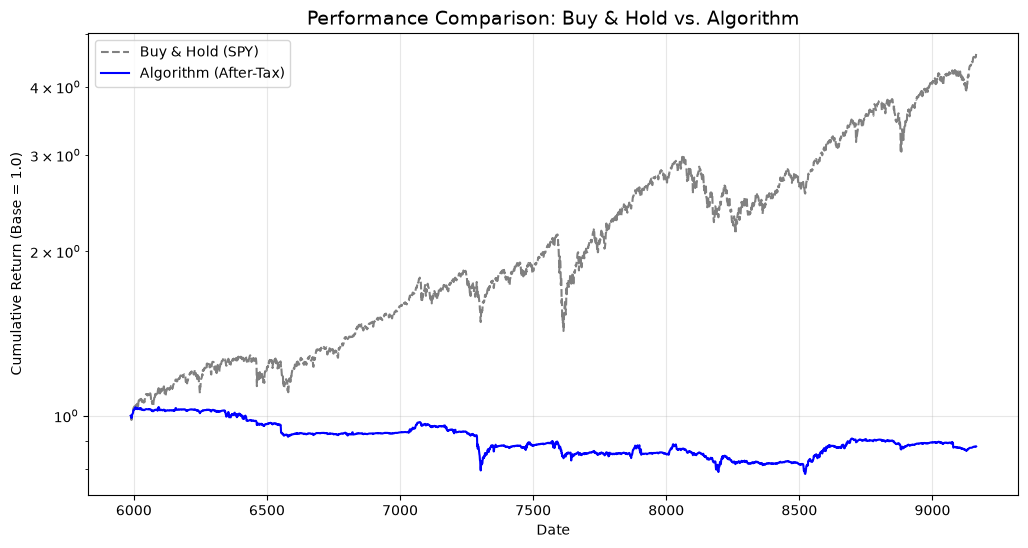

In [60]:
# パフォーマンス指標の計算と要約の作成
trade = (
    v12_df["target_weight"]
    .diff()
    .abs()
    .fillna(0)
)
# 売買回数の計算
gross_ret = (
    v12_df["target_weight"]
    .shift(1)
    .fillna(0)
    *
    v12_df["spy_ret"]
)
# 税金の計算
fee = (trade * BROKER_FEE_RATE)
# スリッページの計算
tax = (np.where(gross_ret > 0, gross_ret, 0) * TOTAL_TAX_RATE)
# 税引後リターンの計算に使用する税金の計算
slippage = (trade * SLIPPAGE_RATE)
# 税引後リターンの計算
after_tax_ret = (gross_ret - fee - tax - slippage)
# 【追加】日次リターンをデータフレームに格納
v12_df["Buy & Hold"] = (1 + v12_df["spy_ret"]).cumprod()
v12_df["Algorithm (After-Tax)"] = (1 + after_tax_ret).cumprod()
# パフォーマンス指標の計算結果を取得
result = calc_metrics(after_tax_ret)
# 年換算の計算
years = (len(v12_df) / 252)
# 年換算の売買回数の計算
turnover = (trade.sum() / 2 / years)
# 経済的価値の判定
economic_value = (
    result["Return"] > 0
    and
    result["CAGR"] > 0
    and
    result["Sharpe"] > 0.5
    and
    abs(result["MDD"]) < 0.15
    and
    turnover <= 24
)
# パフォーマンス指標の要約を作成
summary_df = pd.DataFrame([
    {
        "AfterTaxReturn": result["Return"],
        "AfterTaxCAGR": result["CAGR"],
        "Sharpe": result["Sharpe"],
        "MDD": result["MDD"],
        "Turnover": turnover,
        "EconomicValue": economic_value
    }
])
# CSVファイルとして抽出
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"8_Final_Economic_Value_Test_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = walk_forward_df.copy()
df.to_csv(output_path)
# 保存したCSVファイルのパスを表示する
print("Saved CSV file path:", output_path)
# パフォーマンス指標の要約を表示
display(summary_df)
# 
plt.figure(figsize=(12, 6))
plt.plot(v12_df.index, v12_df["Buy & Hold"], label="Buy & Hold (SPY)", color="gray", linestyle="--")
plt.plot(v12_df.index, v12_df["Algorithm (After-Tax)"], label="Algorithm (After-Tax)", color="blue")
plt.title("Performance Comparison: Buy & Hold vs. Algorithm", fontsize=14)
plt.xlabel("Date")
plt.ylabel("Cumulative Return (Base = 1.0)")
plt.legend(loc="upper left")
plt.grid(True, alpha=0.3)
plt.yscale("log")
# 例: すでに作成済みの fig を保存
output_dir = Path("/workspace/data/figures")
output_dir.mkdir(parents=True, exist_ok=True)
# ファイル名にコードと期間を含める
output_path = output_dir / f"8_Final_Economic_Value_Test_{start}_{end}.png"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
plt.savefig(str(output_path), dpi=300, bbox_inches='tight')
# 保存完了のメッセージを表示
print("saved:", output_path)
plt.show()
plt.close()

In [61]:
expected_signal * expected_weight

-0.1544652650835347

In [62]:
v12_df["signal"].value_counts()

signal
-1    2573
 1     604
Name: count, dtype: int64

In [63]:
v12_df["score"].describe()

count    3177.000000
mean       -2.239534
std         1.569819
min        -3.000000
25%        -3.000000
50%        -3.000000
75%        -3.000000
max         1.000000
Name: score, dtype: float64

In [64]:
v12_df[
    [
        "svxy_z",
        "spy_rci9",
        "spy_macd_hist",
        "spy_macd_gc",
        "score",
        "signal"
    ]
].tail(20)

,svxy_z,spy_rci9,spy_macd_hist,spy_macd_gc,score,signal
9145,-0.578230,95.000000,3.528724,0.000000,-3.0,-1
9146,0.644961,93.333333,2.828976,0.000000,-3.0,-1
9147,0.881475,88.333333,2.100760,0.000000,-3.0,-1
9148,-0.958143,88.333333,1.670647,0.000000,-3.0,-1
9149,-0.207198,88.333333,1.635965,0.000000,-3.0,-1
9150,0.649156,91.666667,1.351957,0.000000,-3.0,-1
9151,-0.873344,91.666667,1.106354,-0.761265,-3.0,-1
9152,0.416207,91.666667,1.192965,0.000000,-3.0,-1
9153,0.057103,91.666667,1.512295,0.000000,-3.0,-1
9154,-0.138426,95.000000,1.512194,0.000000,-3.0,-1


In [65]:
(
    v12_df["signal"]
    !=
    v12_df["signal"].shift(1)
).sum()

np.int64(46)

In [66]:
v12_df["score"].value_counts().head(20)

score
-3.0    2573
 1.0     604
Name: count, dtype: int64

In [67]:
v12_df["score"].head()
v12_df["score"].value_counts().head(20)

score
-3.0    2573
 1.0     604
Name: count, dtype: int64

In [68]:
print(
    v12_df["signal"]
    .value_counts(normalize=True)
)

signal
-1    0.809884
 1    0.190116
Name: proportion, dtype: float64
